# Predicción pronóstica en síndromes mielodisplásicos mediante Deep Learning e IPSS-M
**Maritza Medina Giraldo** — TFM, Máster Universitario en Bioinformática (UNIR)

Cuaderno de resultados. Lee las tablas y figuras generadas por el pipeline (`run_all.sh`). Para reentrenar los modelos, ejecute los scripts de `scripts/` en orden.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
T, F = ROOT / 'results/tables', ROOT / 'results/figures'
pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 3)
def fig(n, w=650): display(Image(filename=str(F / f'{n}.png'), width=w))

## 1. Cohorte y variable objetivo (OE1)

In [2]:
pd.read_csv(T / 'flujo_pacientes.csv', index_col=0)

,n
Cohorte IPSS-M (cBioPortal),2957
Sin dato de LFS o evento ambiguo (excluidos),347
Cohorte analítica,2610
Transformación a LMA (AML_T = 1),472
Sin transformación (AML_T = 0),2138
"· de ellos, muerte sin LMA",874


In [3]:
pd.read_csv(T / 'diccionario_predictores.csv').groupby('tipo').size()

tipo
binary         70
categorical     3
numeric        16
dtype: int64

In [4]:
pd.read_csv(T / 'tabla1_descriptiva.csv')

,variable,Sin LMA (n=2138),LMA (n=472),% faltantes,p,prueba
0,Edad (años),73.0 [64.0–79.0],69.5 [63.0–76.0],0.0,1.047e-04,Mann-Whitney U
1,Blastos MO (%),3.0 [1.0–5.2],7.0 [3.0–12.0],2.2,1.810e-40,Mann-Whitney U
2,Blastos SP (%),0.0 [0.0–0.0],0.0 [0.0–0.0],18.1,2.483e-11,Mann-Whitney U
3,Hemoglobina (g/dL),9.7 [8.5–11.2],9.4 [8.3–10.8],2.1,2.737e-02,Mann-Whitney U
4,Plaquetas (×10⁹/L),138.5 [71.2–246.0],105.0 [56.0–175.8],2.5,1.423e-08,Mann-Whitney U
5,Leucocitos (×10⁹/L),4.1 [2.8–6.2],3.4 [2.3–5.0],7.2,4.901e-07,Mann-Whitney U
6,Neutrófilos (×10⁹/L),2.0 [1.0–3.5],1.4 [0.9–2.6],4.1,3.207e-12,Mann-Whitney U
7,Monocitos (×10⁹/L),0.4 [0.2–0.7],0.2 [0.1–0.6],16.2,3.871e-09,Mann-Whitney U
8,TMB (no sinónimas),8.7 [6.5–13.0],10.9 [6.5–15.2],0.0,1.156e-10,Mann-Whitney U
9,Nº genes conductores mutados,2.0 [1.0–4.0],3.0 [2.0–5.0],0.0,6.254e-19,Mann-Whitney U


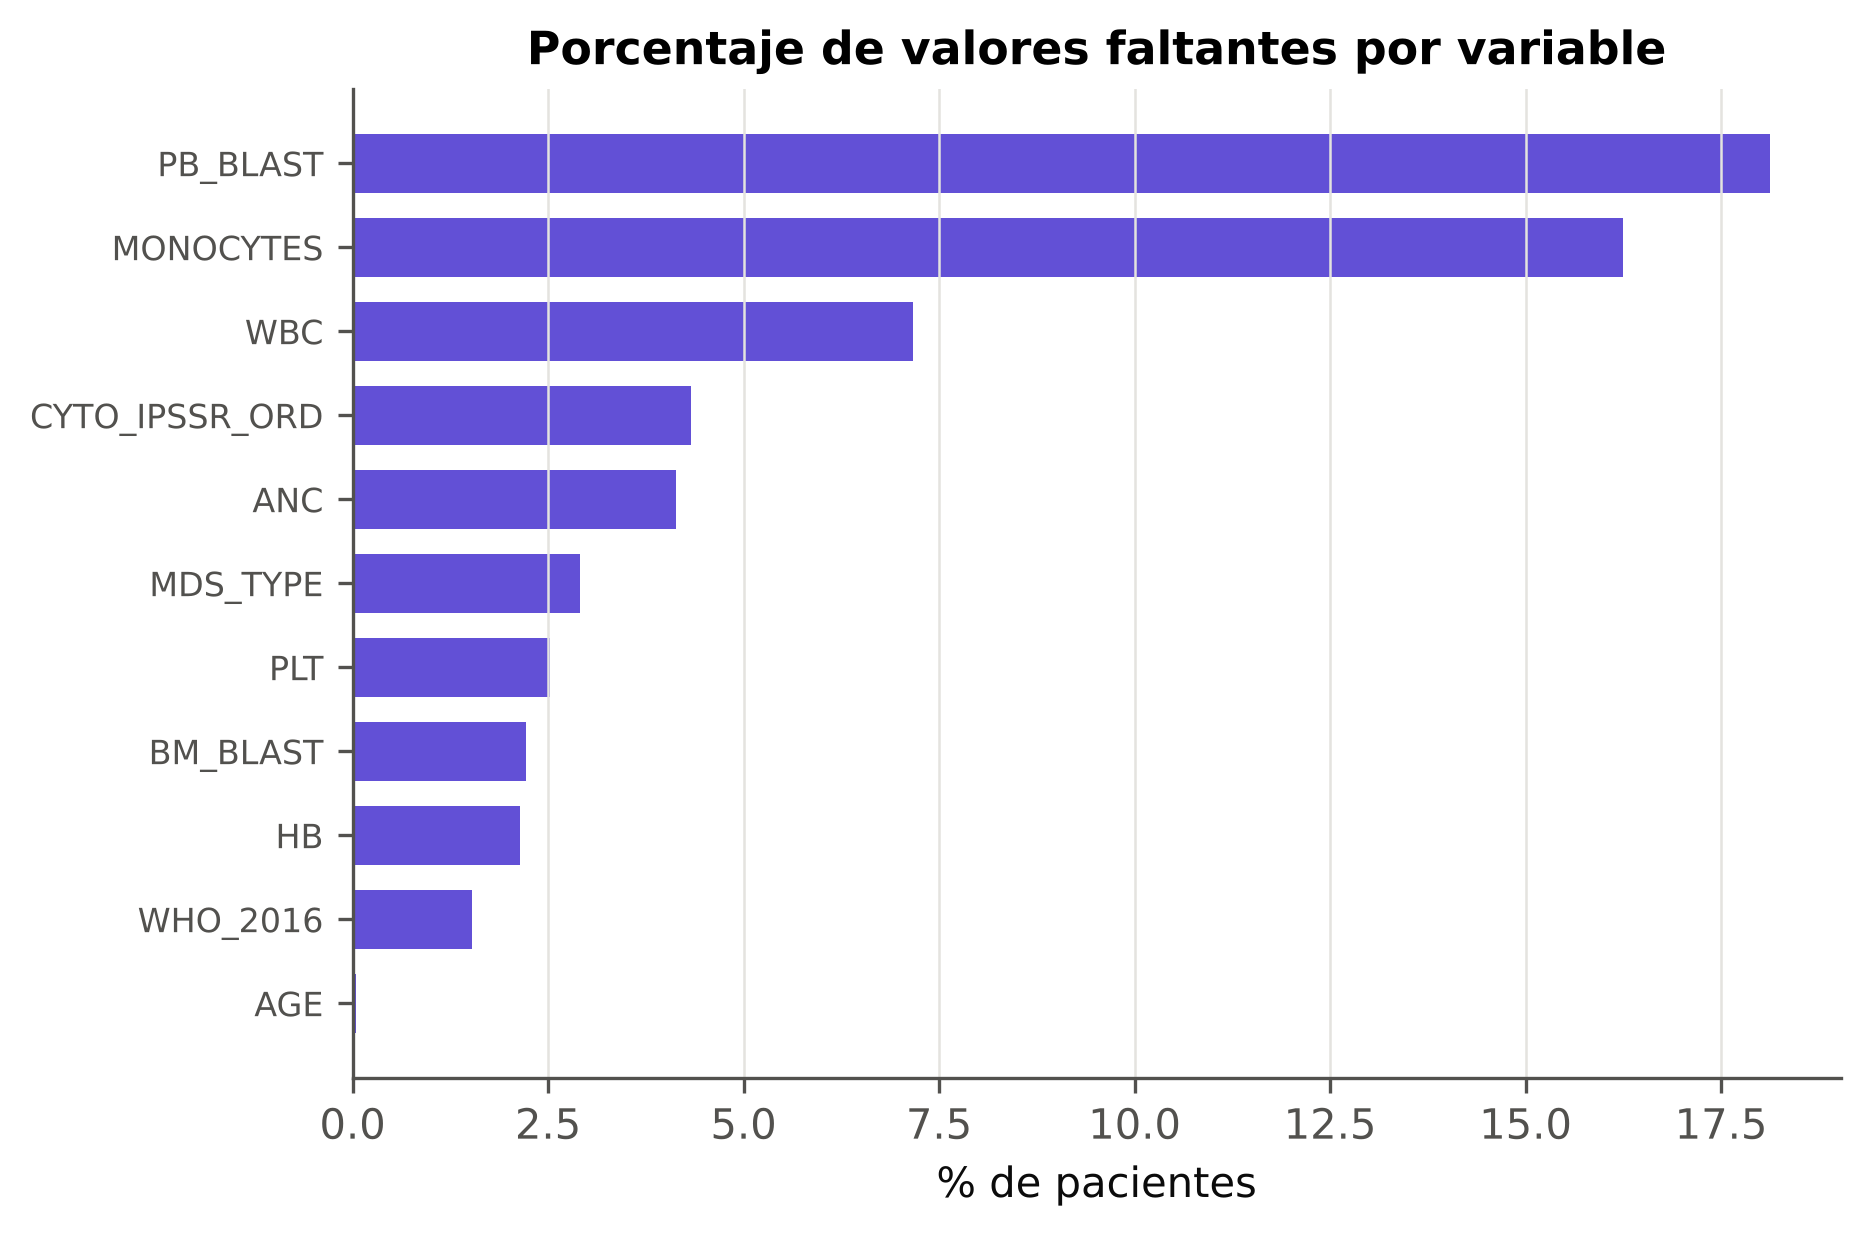

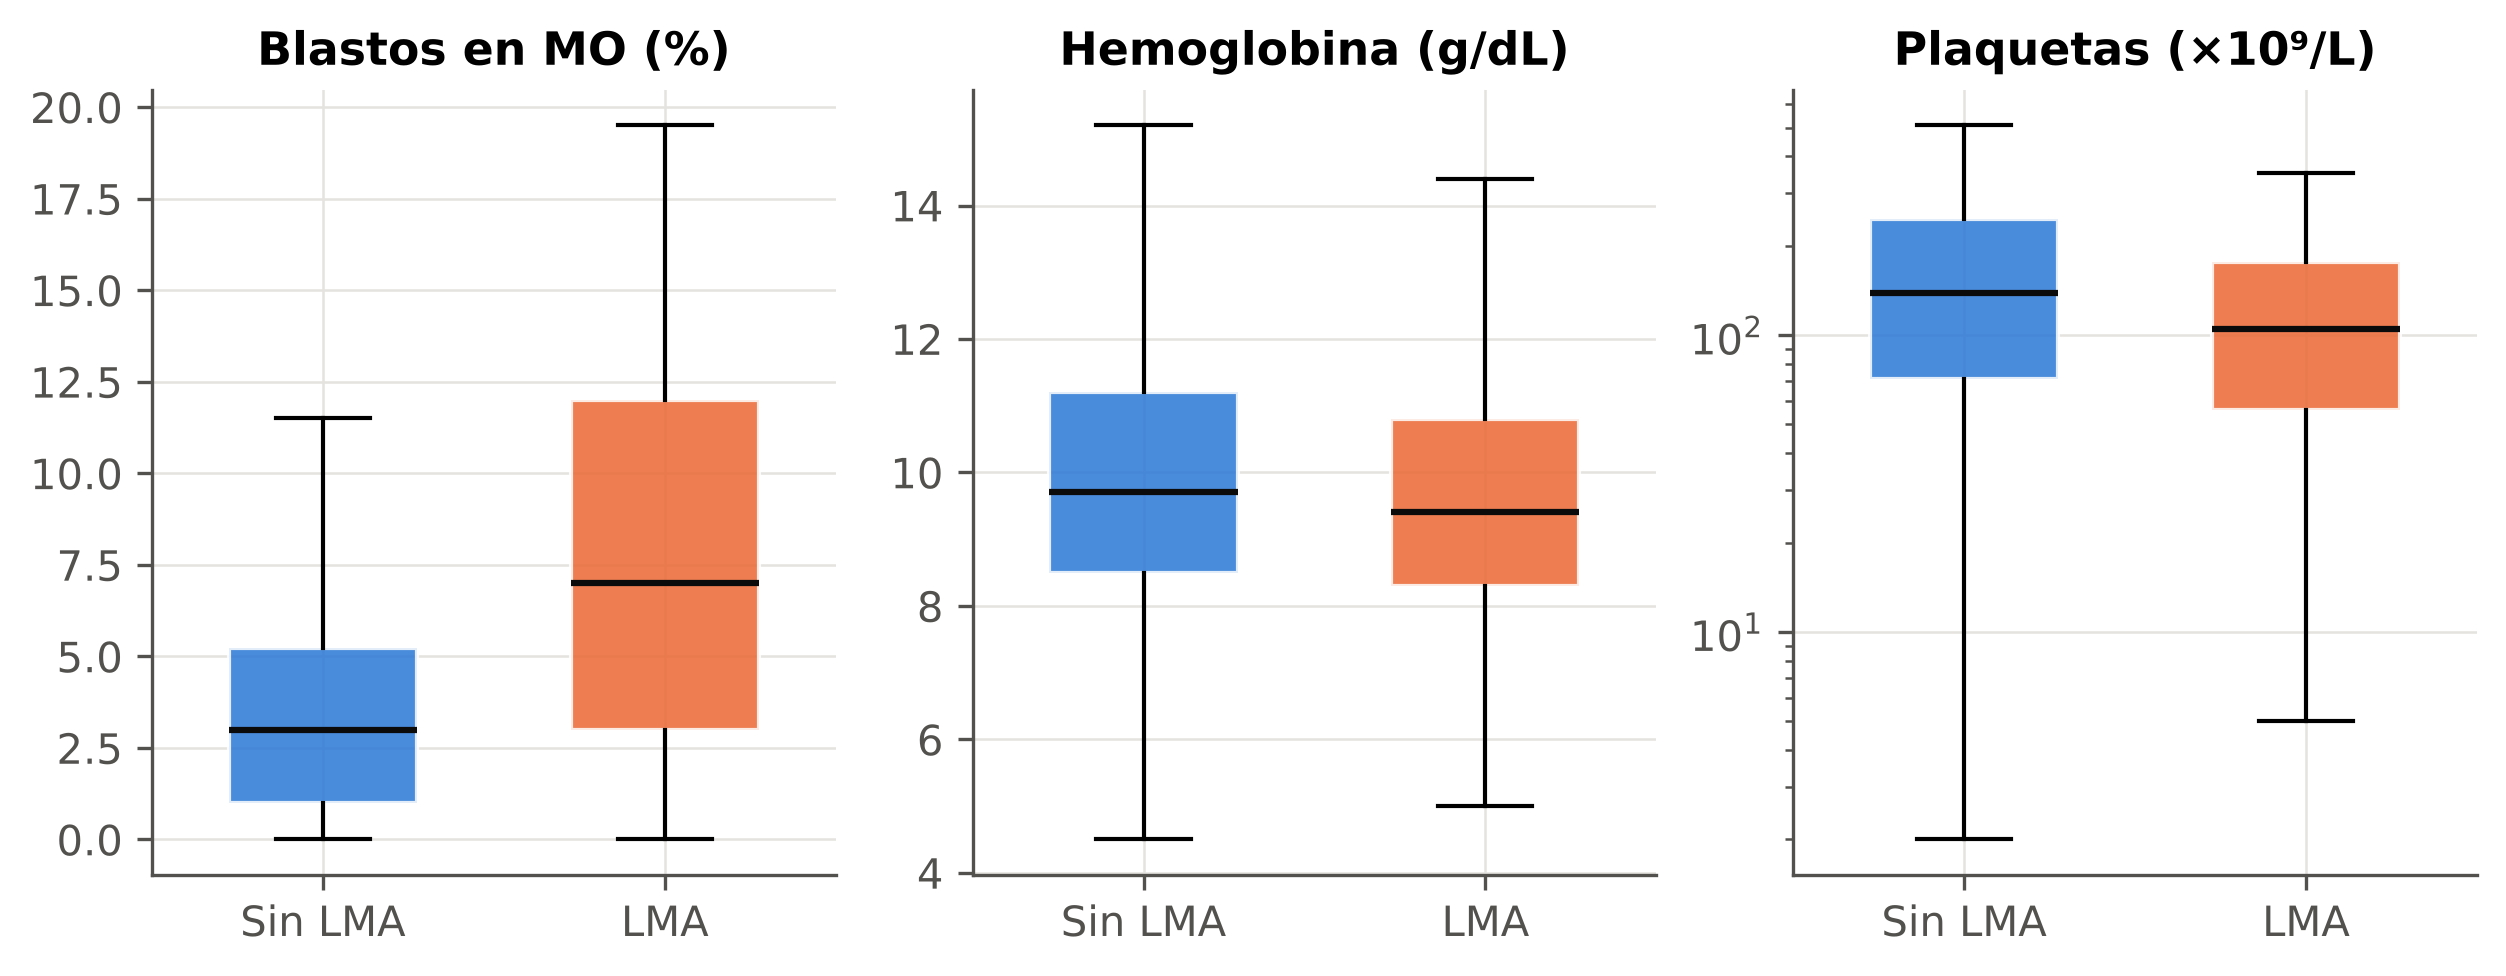

In [5]:
fig('eda_faltantes', 500); fig('eda_clinicas_por_desenlace', 800)

## 2. Factores asociados a la progresión a LMA (OE2)

In [6]:
pd.read_csv(T / 'asociacion_univariante_alteraciones.csv').head(20)

,variable,n_alterados,frecuencia_%,LMA_en_alterados_%,LMA_en_no_alterados_%,OR,OR_IC2.5,OR_IC97.5,p,q_FDR
0,TP53_MULTIHIT,202,7.739,39.109,16.321,3.297,2.438,4.459,1.695e-13,1.186e-11
1,MUT_RUNX1,327,12.529,32.722,15.988,2.559,1.981,3.306,6.140e-12,2.149e-10
2,MUT_TP53,301,11.533,32.558,16.197,2.502,1.920,3.260,9.334e-11,2.178e-09
3,COMPLEX_KARYOTYPE,249,9.540,34.137,16.391,2.648,1.995,3.515,1.254e-10,2.195e-09
4,MUT_STAG2,233,8.927,34.335,16.491,2.653,1.984,3.548,3.646e-10,5.105e-09
5,MLL_PTD,62,2.375,51.613,17.268,5.100,3.079,8.449,1.381e-09,1.611e-08
6,MUT_SF3B1,644,24.674,10.559,20.549,0.459,0.349,0.603,2.955e-09,2.955e-08
7,MUT_U2AF1,237,9.080,32.911,16.603,2.470,1.846,3.304,8.097e-09,6.639e-08
8,TP53_LOCUS_LOH,138,5.287,38.406,16.950,3.063,2.142,4.379,8.536e-09,6.639e-08
9,CYTO_DEL7_7Q,211,8.084,33.649,16.715,2.533,1.869,3.434,1.239e-08,8.670e-08


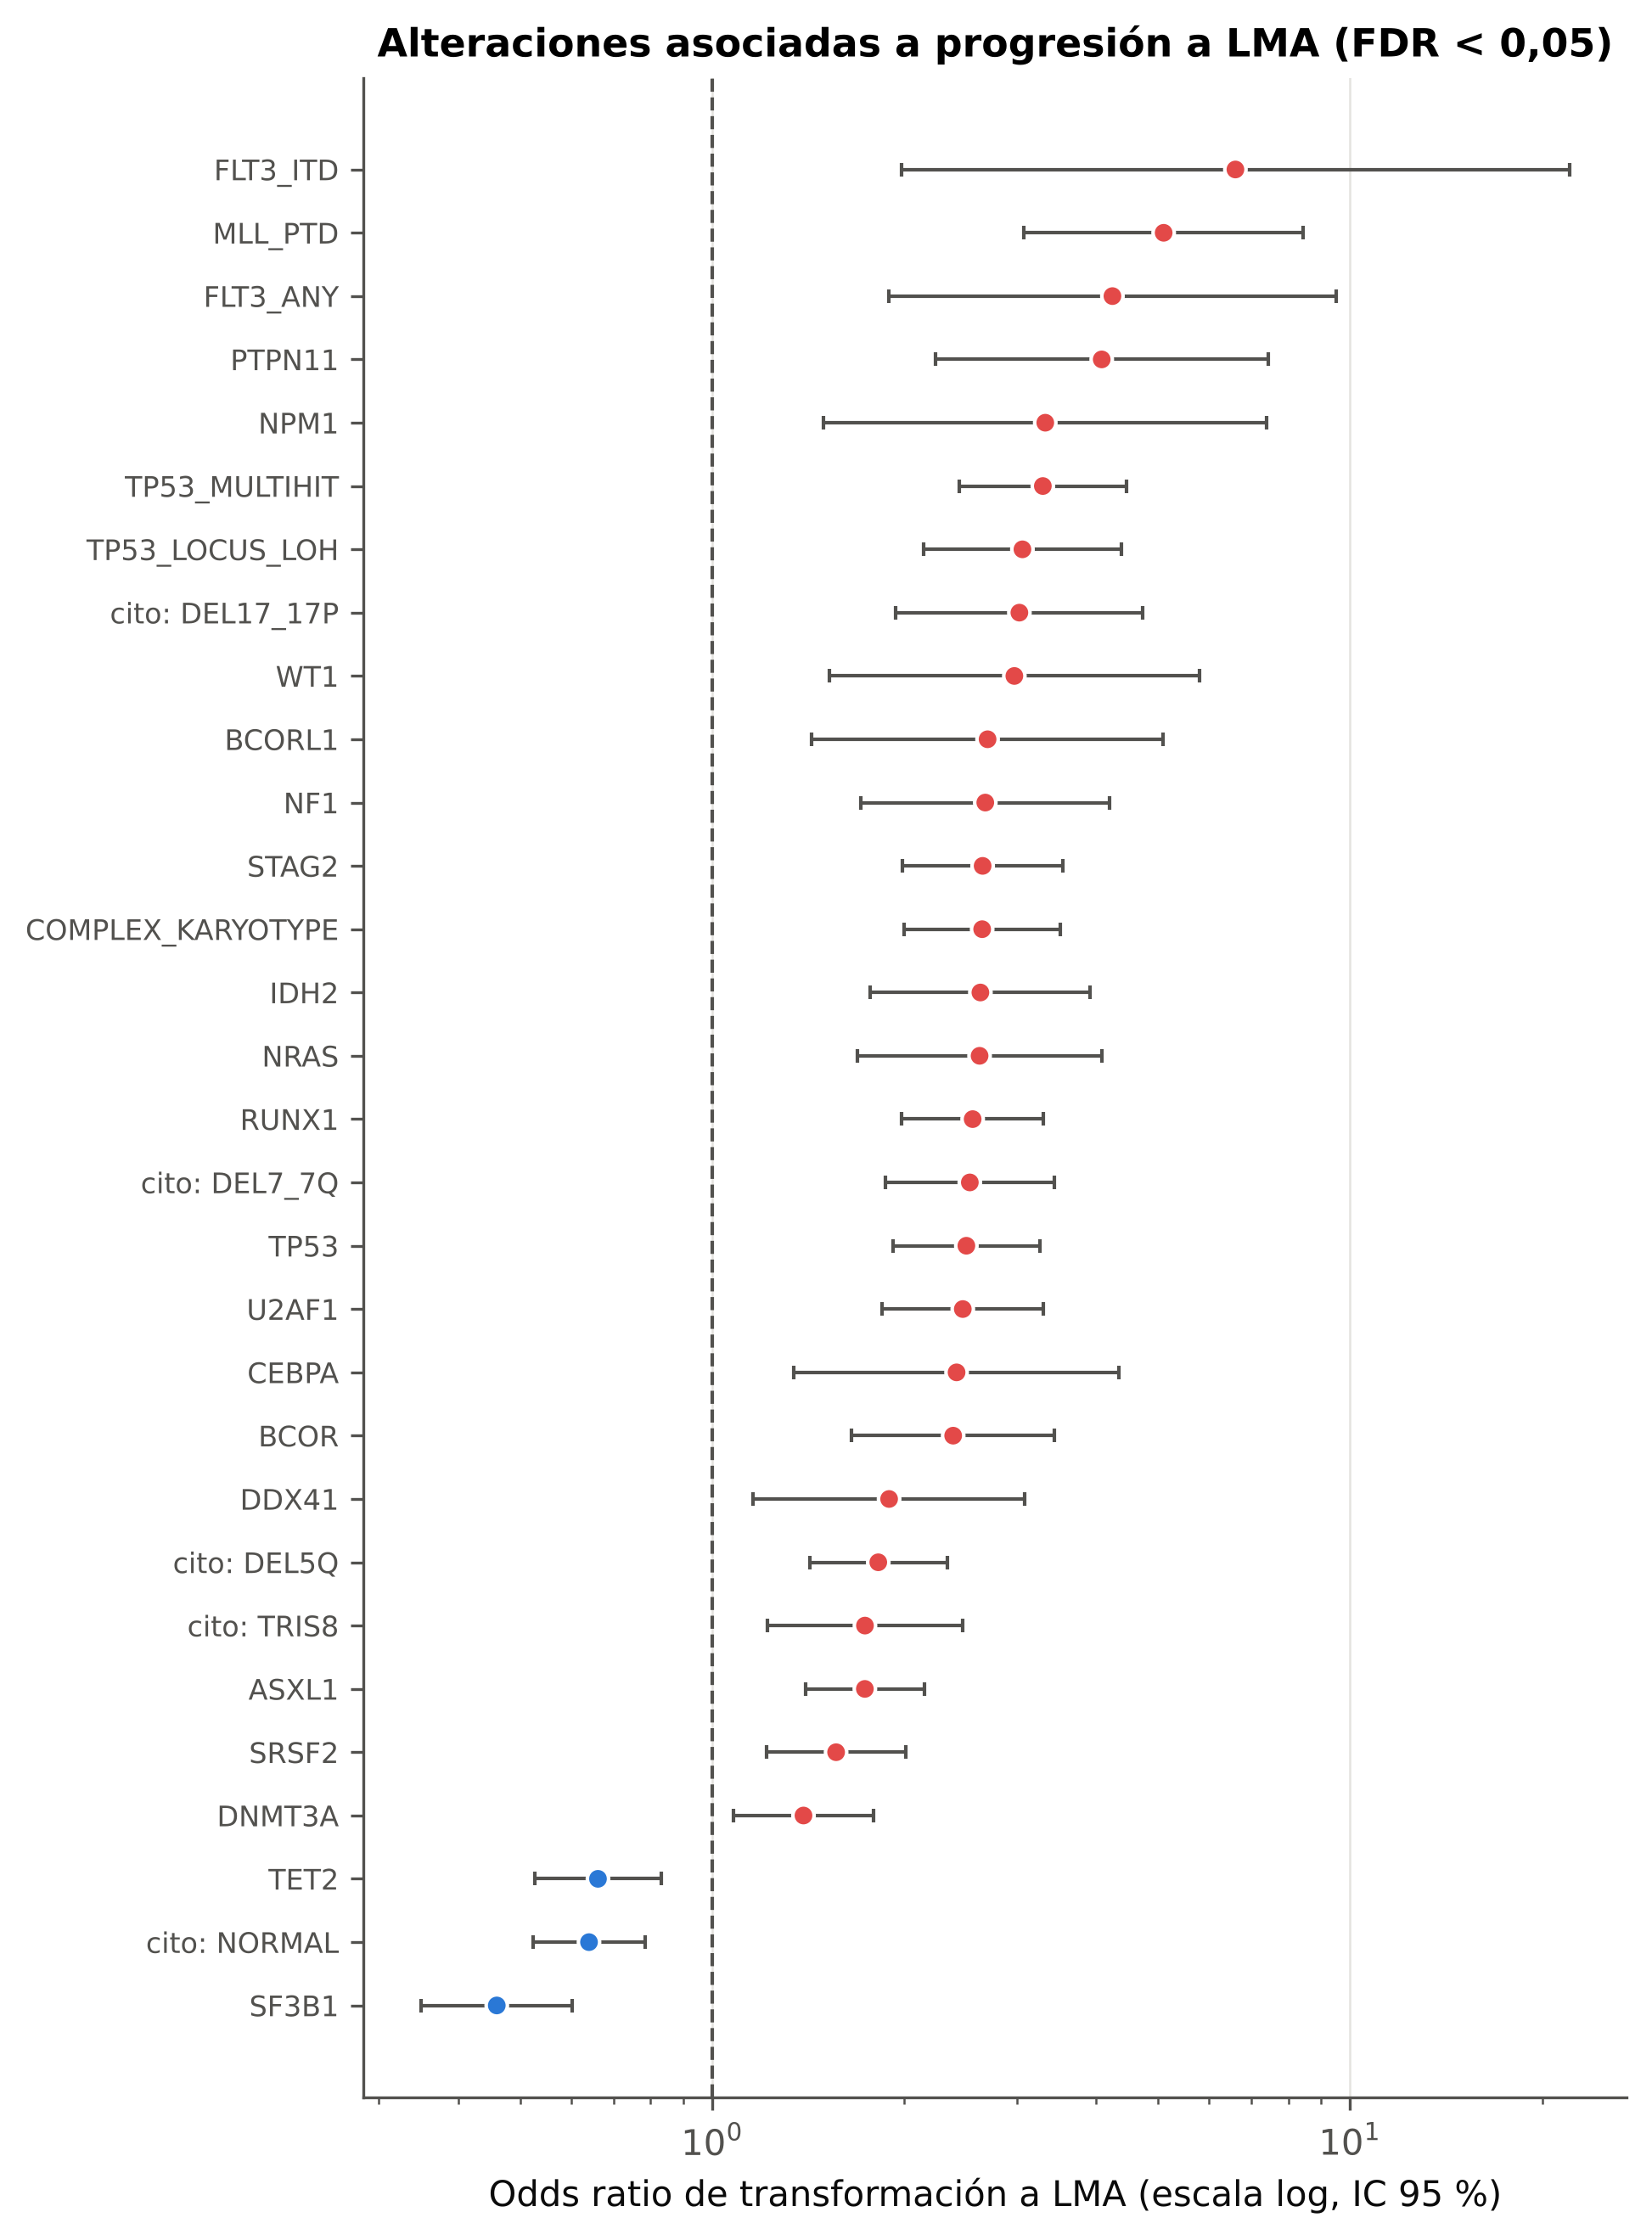

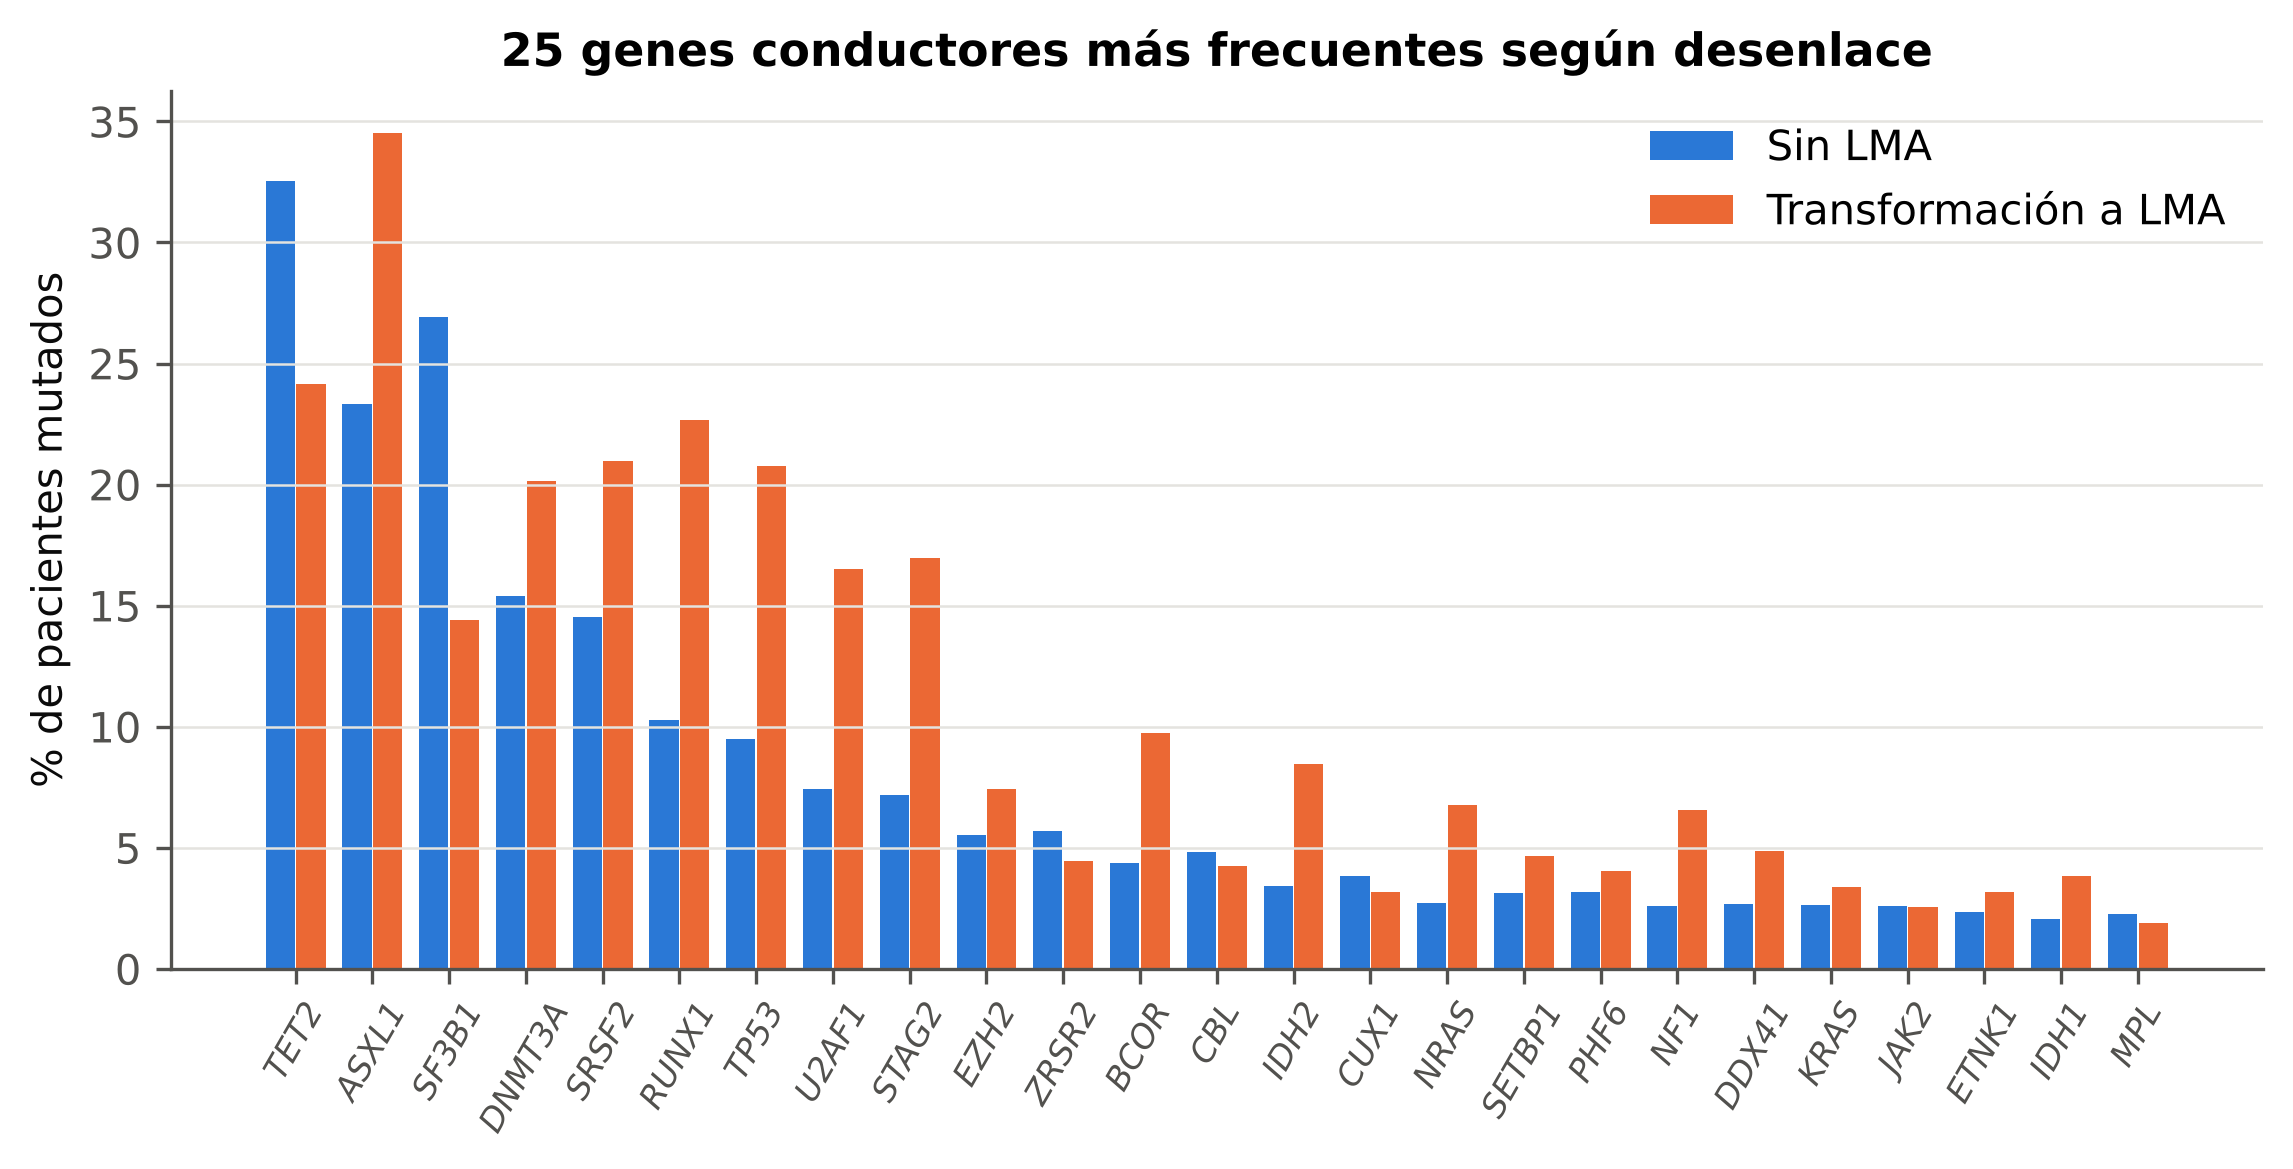

In [7]:
fig('forest_univariante', 550); fig('frecuencia_mutaciones', 850)

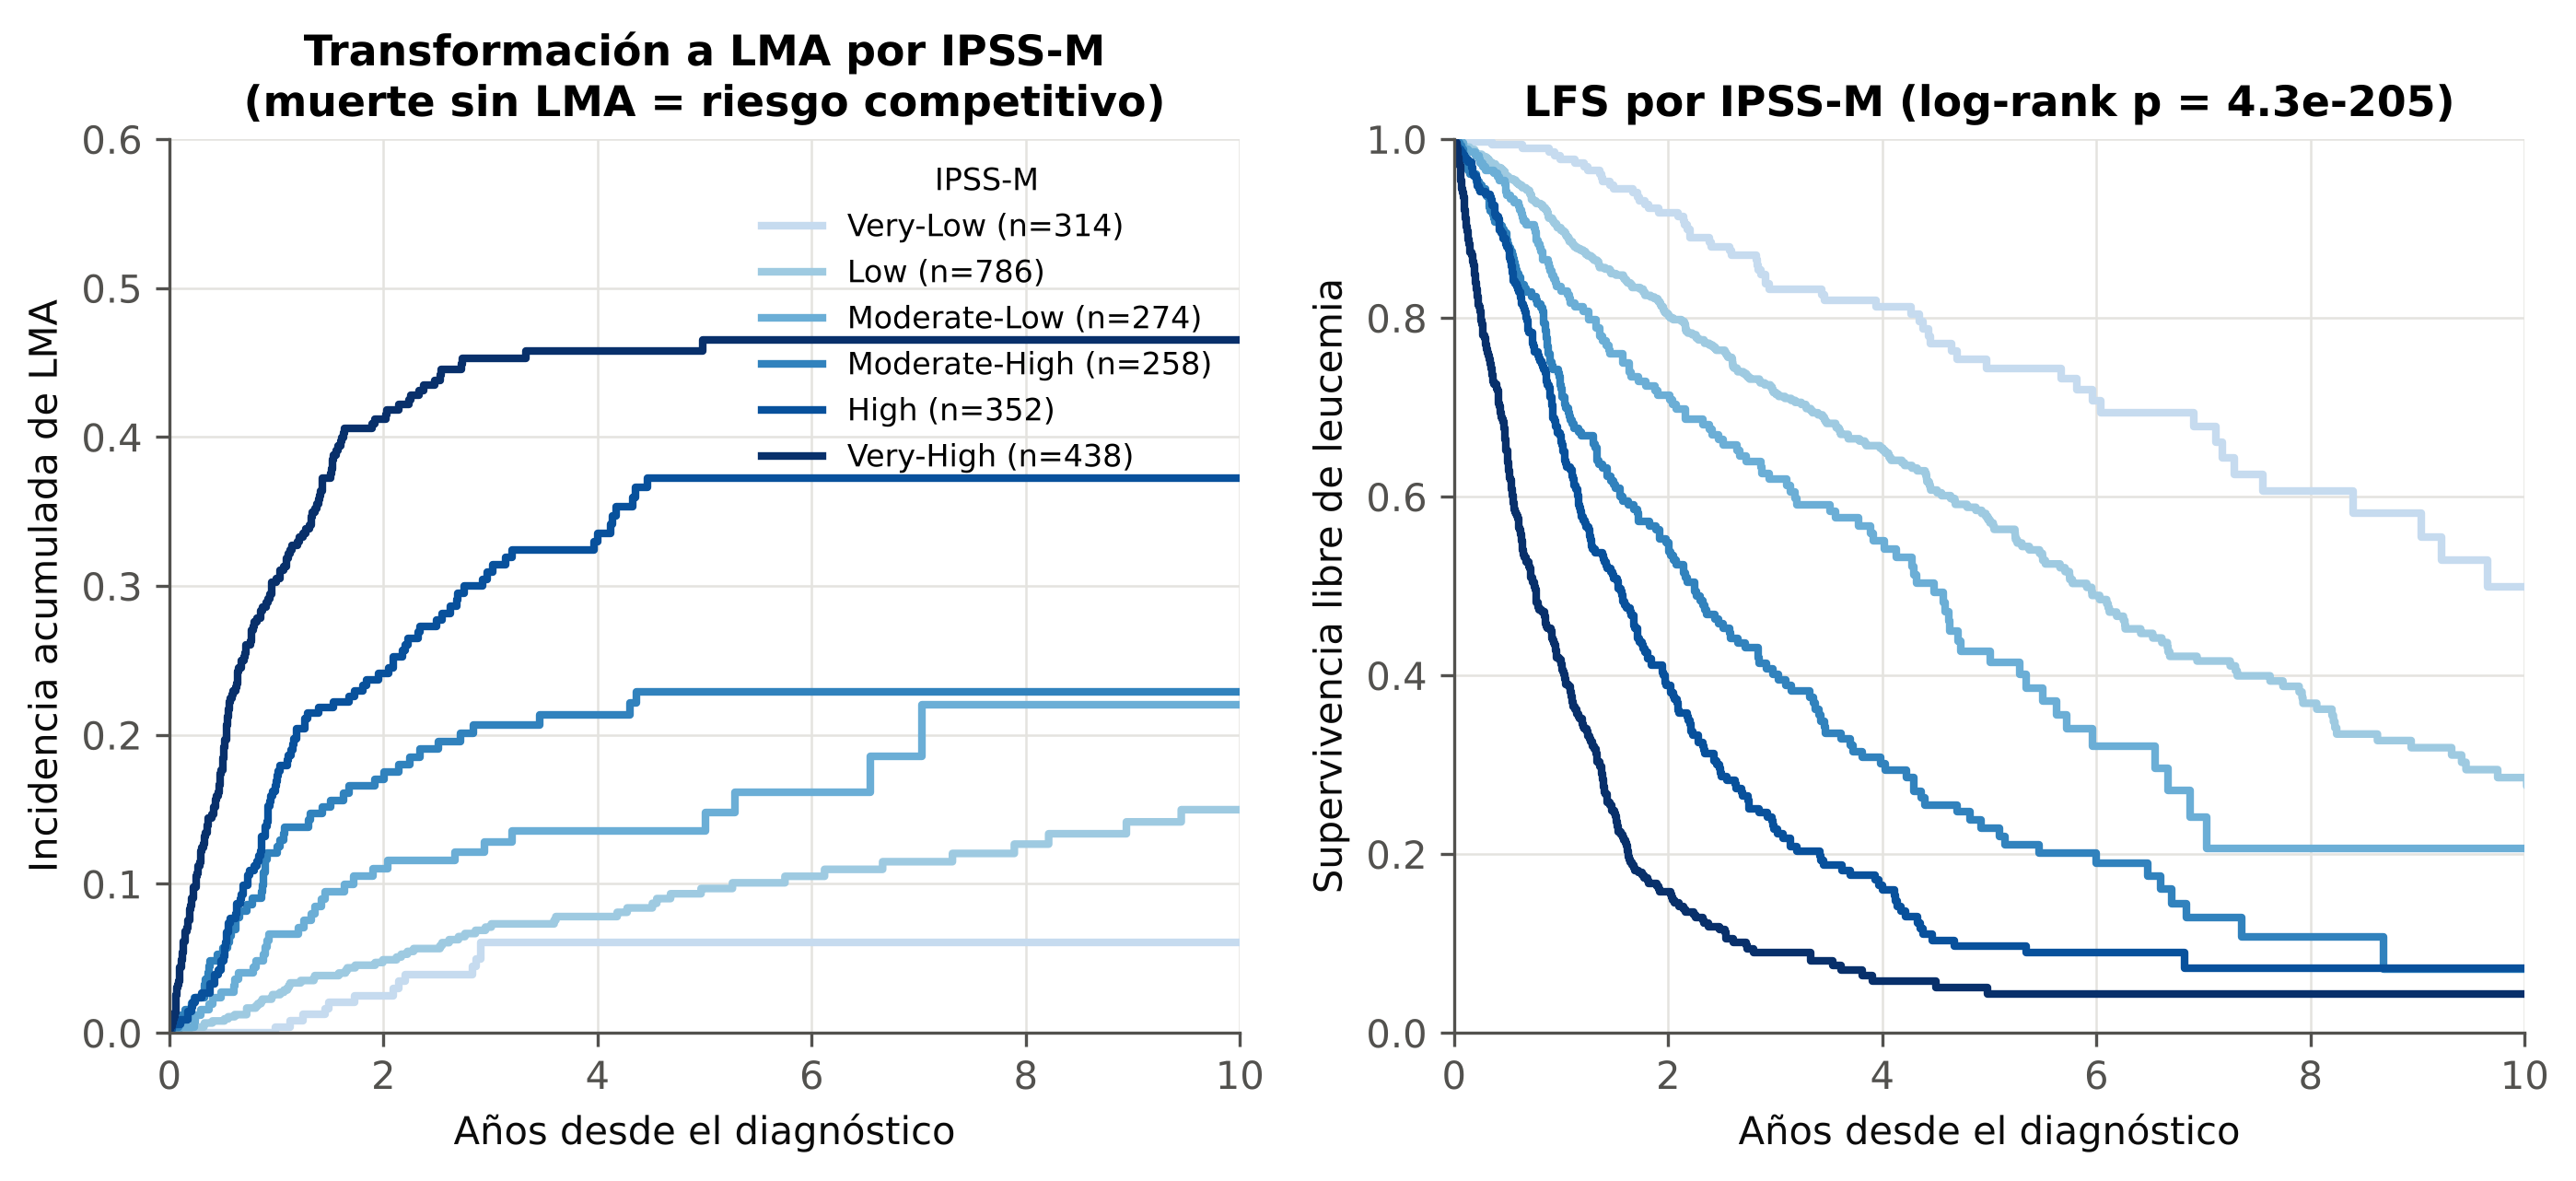

incidencia_acumulada_LMA_%            
años                                   1     3     5
IPSS-M                                              
Very-Low                             0.4   6.1   6.1
Low                                  2.6   7.1   9.7
Moderate-Low                         6.6  12.8  13.5
Moderate-High                       12.1  20.7  22.9
High                                16.9  30.9  37.3
Very-High                           30.5  45.3  46.5

In [8]:
fig('incidencia_LMA_por_IPSSM', 900)
pd.read_csv(T / 'incidencia_acumulada_LMA_IPSSM.csv', header=[0, 1], index_col=0)

## 3. Red neuronal: hiperparámetros y desbalance (OE2)

In [9]:
print(json.dumps(json.load(open(ROOT / 'results/models/mejores_hiperparametros.json')), indent=2, ensure_ascii=False))
pd.read_csv(T / 'busqueda_hiperparametros_red.csv').head()

{
  "Regresión logística": {
    "clf__C": 0.1
  },
  "Random forest": {
    "clf__max_depth": null,
    "clf__max_features": 0.3,
    "clf__min_samples_leaf": 5
  },
  "Red neuronal (DNN)": {
    "clf__learning_rate": 0.0003,
    "clf__l2": 0.0001,
    "clf__hidden_units": [
      128,
      64
    ],
    "clf__dropout": 0.5,
    "clf__batch_size": 64
  }
}


,param_clf__learning_rate,param_clf__l2,param_clf__hidden_units,param_clf__dropout,param_clf__batch_size,mean_test_score,std_test_score,rank_test_score
0,3.000e-04,1.000e-04,"(128, 64)",0.5,64,0.369,0.040,1
1,1.000e-03,1.000e-05,"(64, 32)",0.2,64,0.364,0.029,2
2,1.000e-03,1.000e-05,"(256, 128)",0.5,128,0.363,0.046,3
3,3.000e-03,1.000e-04,"(32,)",0.1,128,0.362,0.039,4
4,3.000e-03,1.000e-03,"(32,)",0.4,32,0.362,0.038,5


,estrategia,AUC-ROC,AUC-PR,F1,Sensibilidad
0,Sin corrección,0.750 ± 0.014,0.373 ± 0.044,0.302 ± 0.069,0.251 ± 0.071
1,Pesos de clase,0.742 ± 0.017,0.369 ± 0.040,0.432 ± 0.020,0.685 ± 0.037
2,SMOTE,0.699 ± 0.024,0.345 ± 0.054,0.341 ± 0.034,0.325 ± 0.034


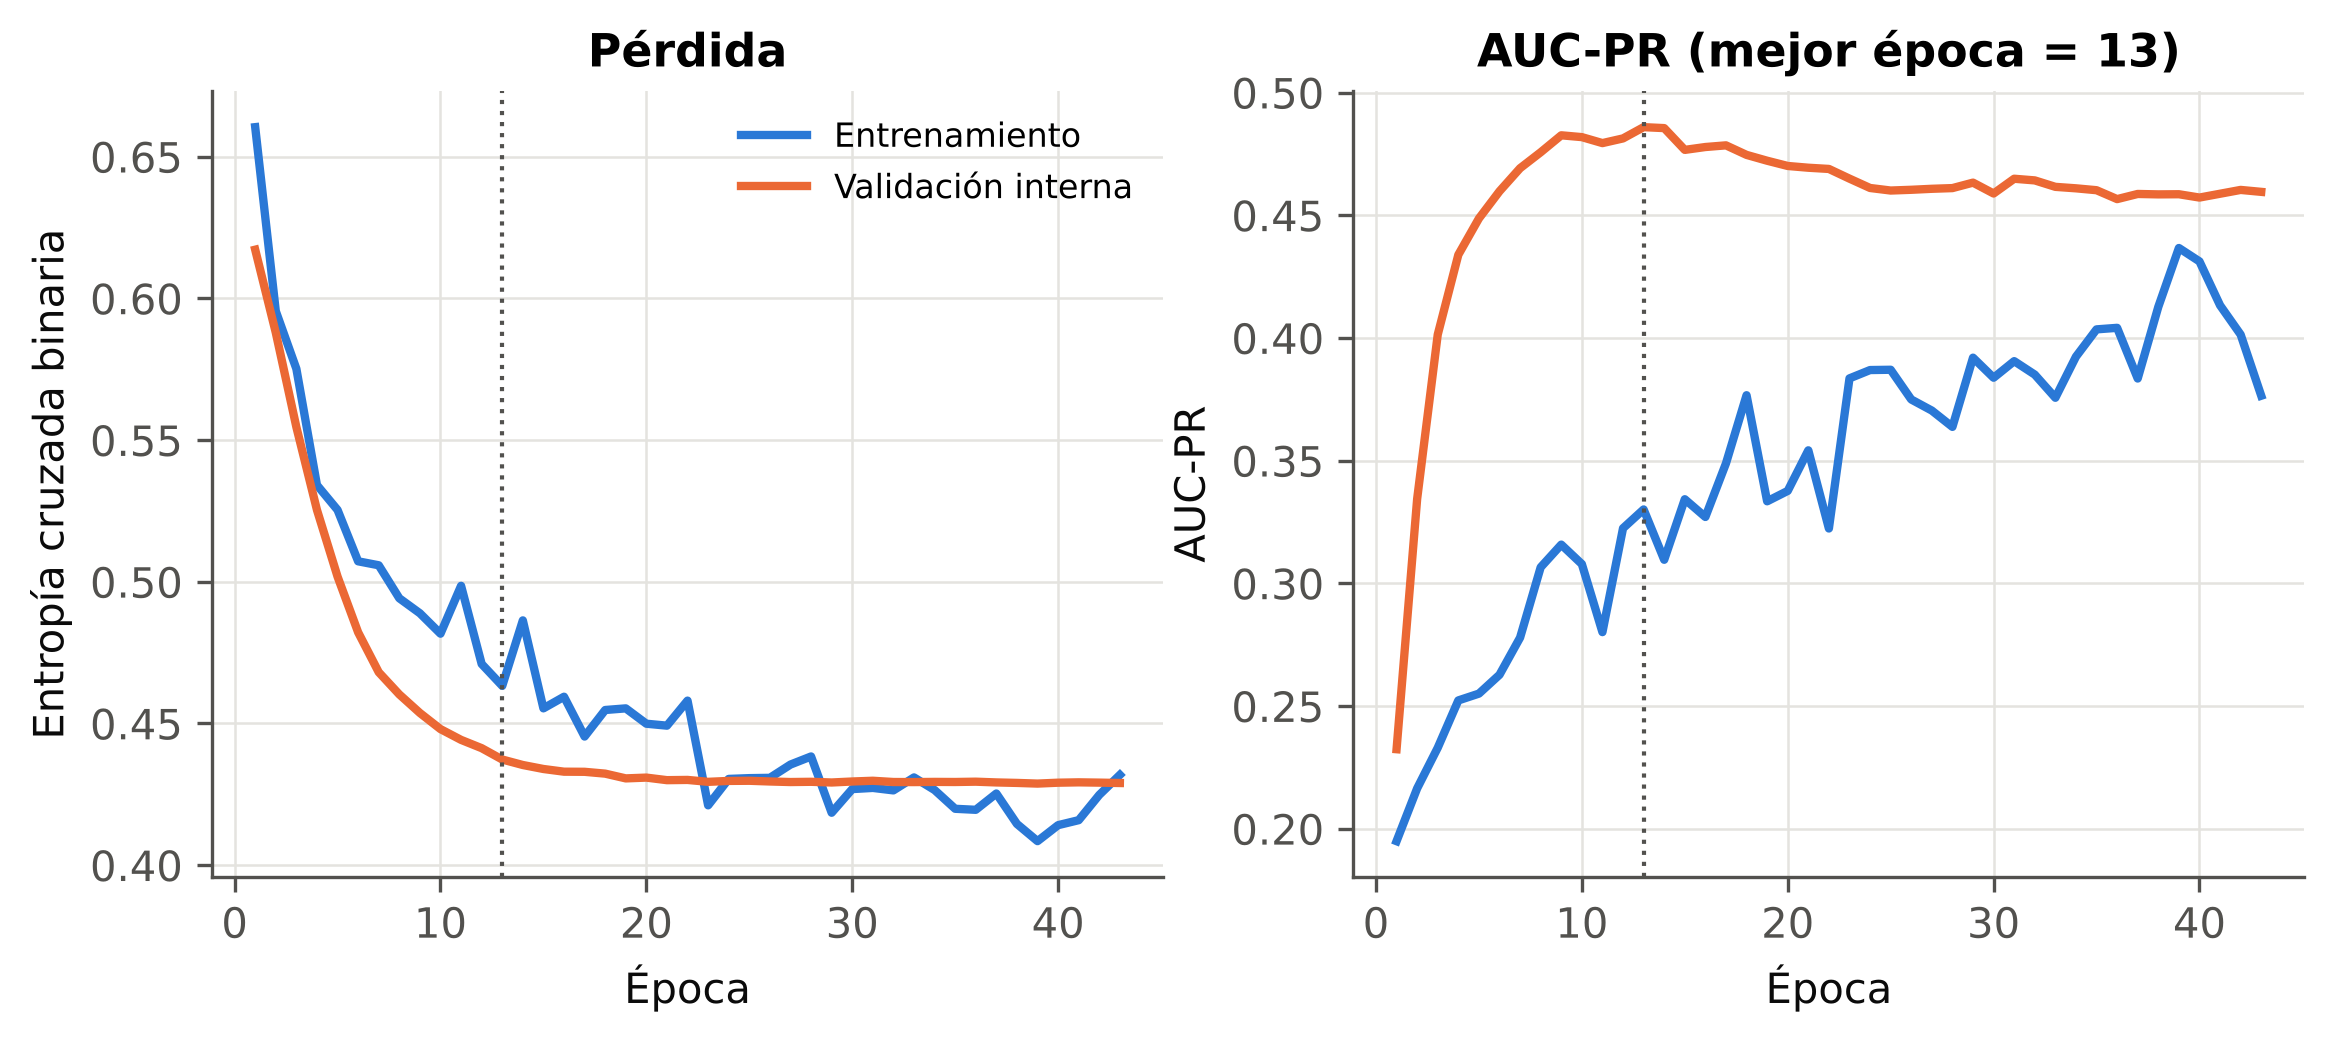

In [10]:
display(pd.read_csv(T / 'dnn_estrategias_desbalance.csv')); fig('dnn_curvas_entrenamiento', 850)

## 4. Validación cruzada y conjunto de prueba (OE3)

AUC-ROC        AUC-PR       
                       mean    std   mean    std
modelo                                          
IPSS-M (puntuación)   0.751  0.023  0.378  0.035
IPSS-R (puntuación)   0.706  0.040  0.321  0.043
Random forest         0.771  0.030  0.407  0.053
Red neuronal (DNN)    0.750  0.016  0.373  0.049
Regresión logística   0.765  0.022  0.402  0.035

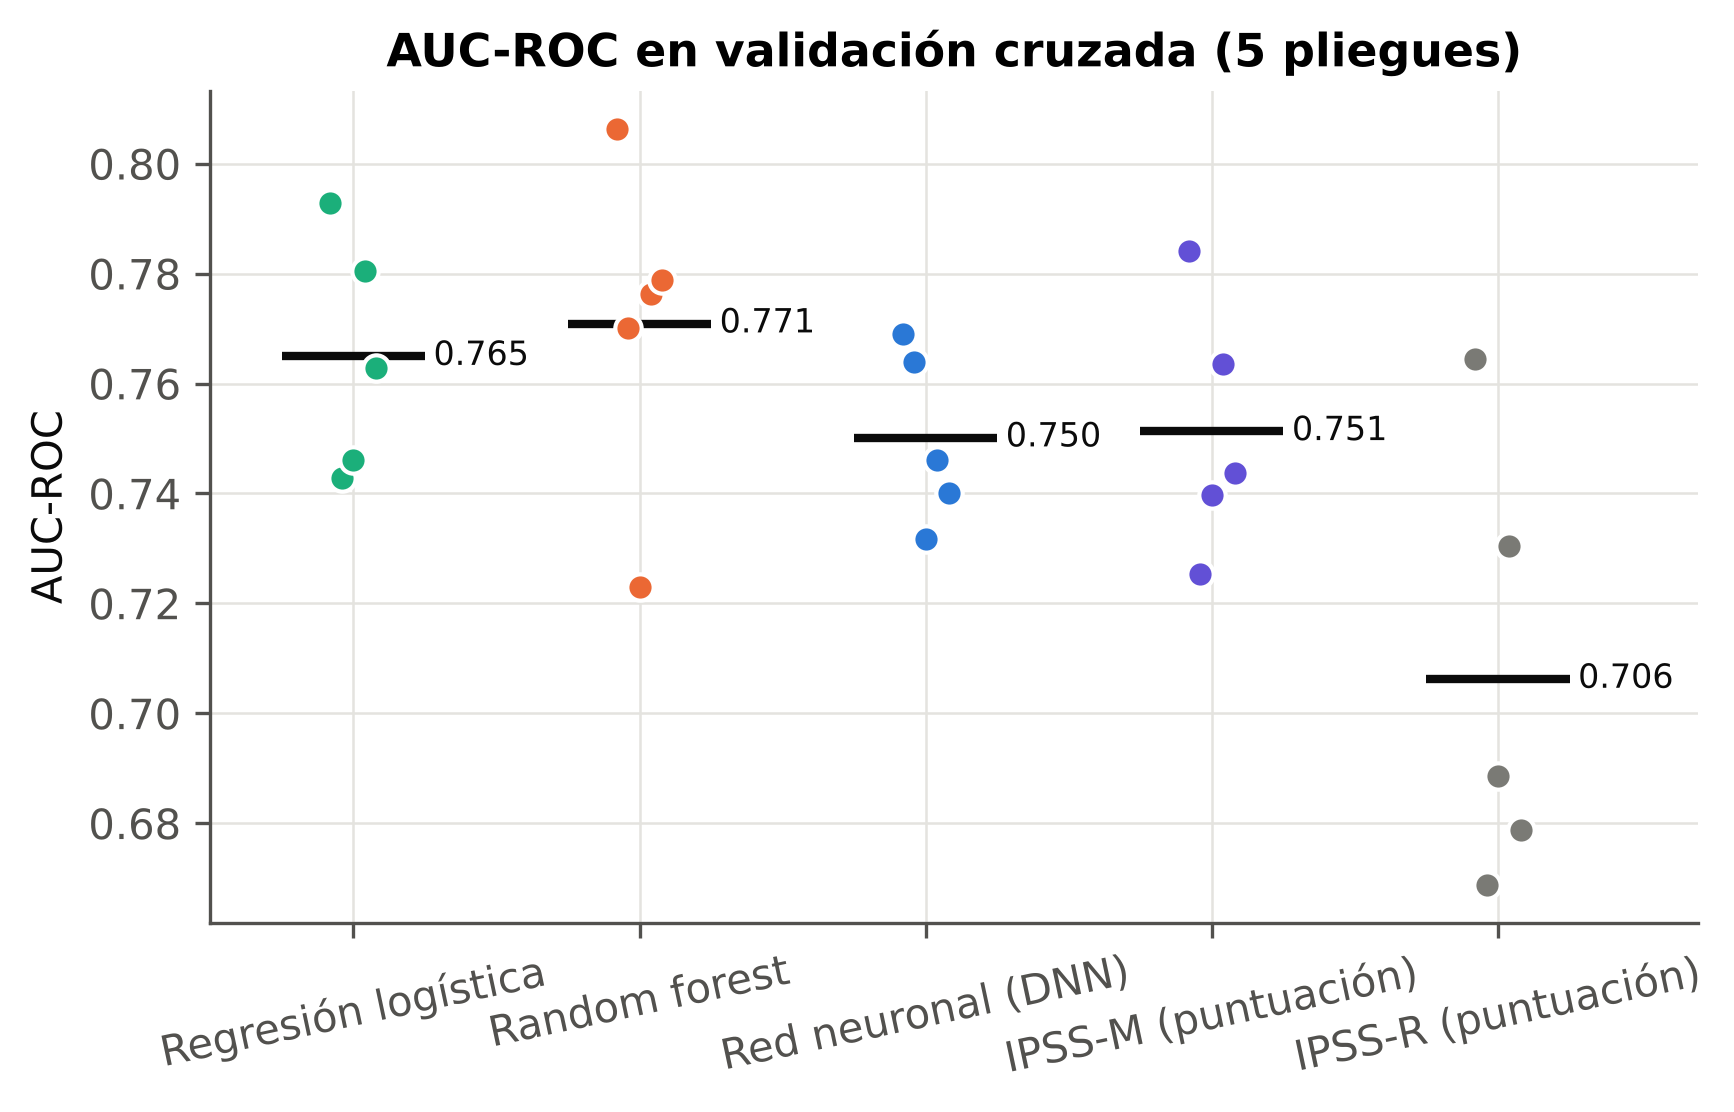

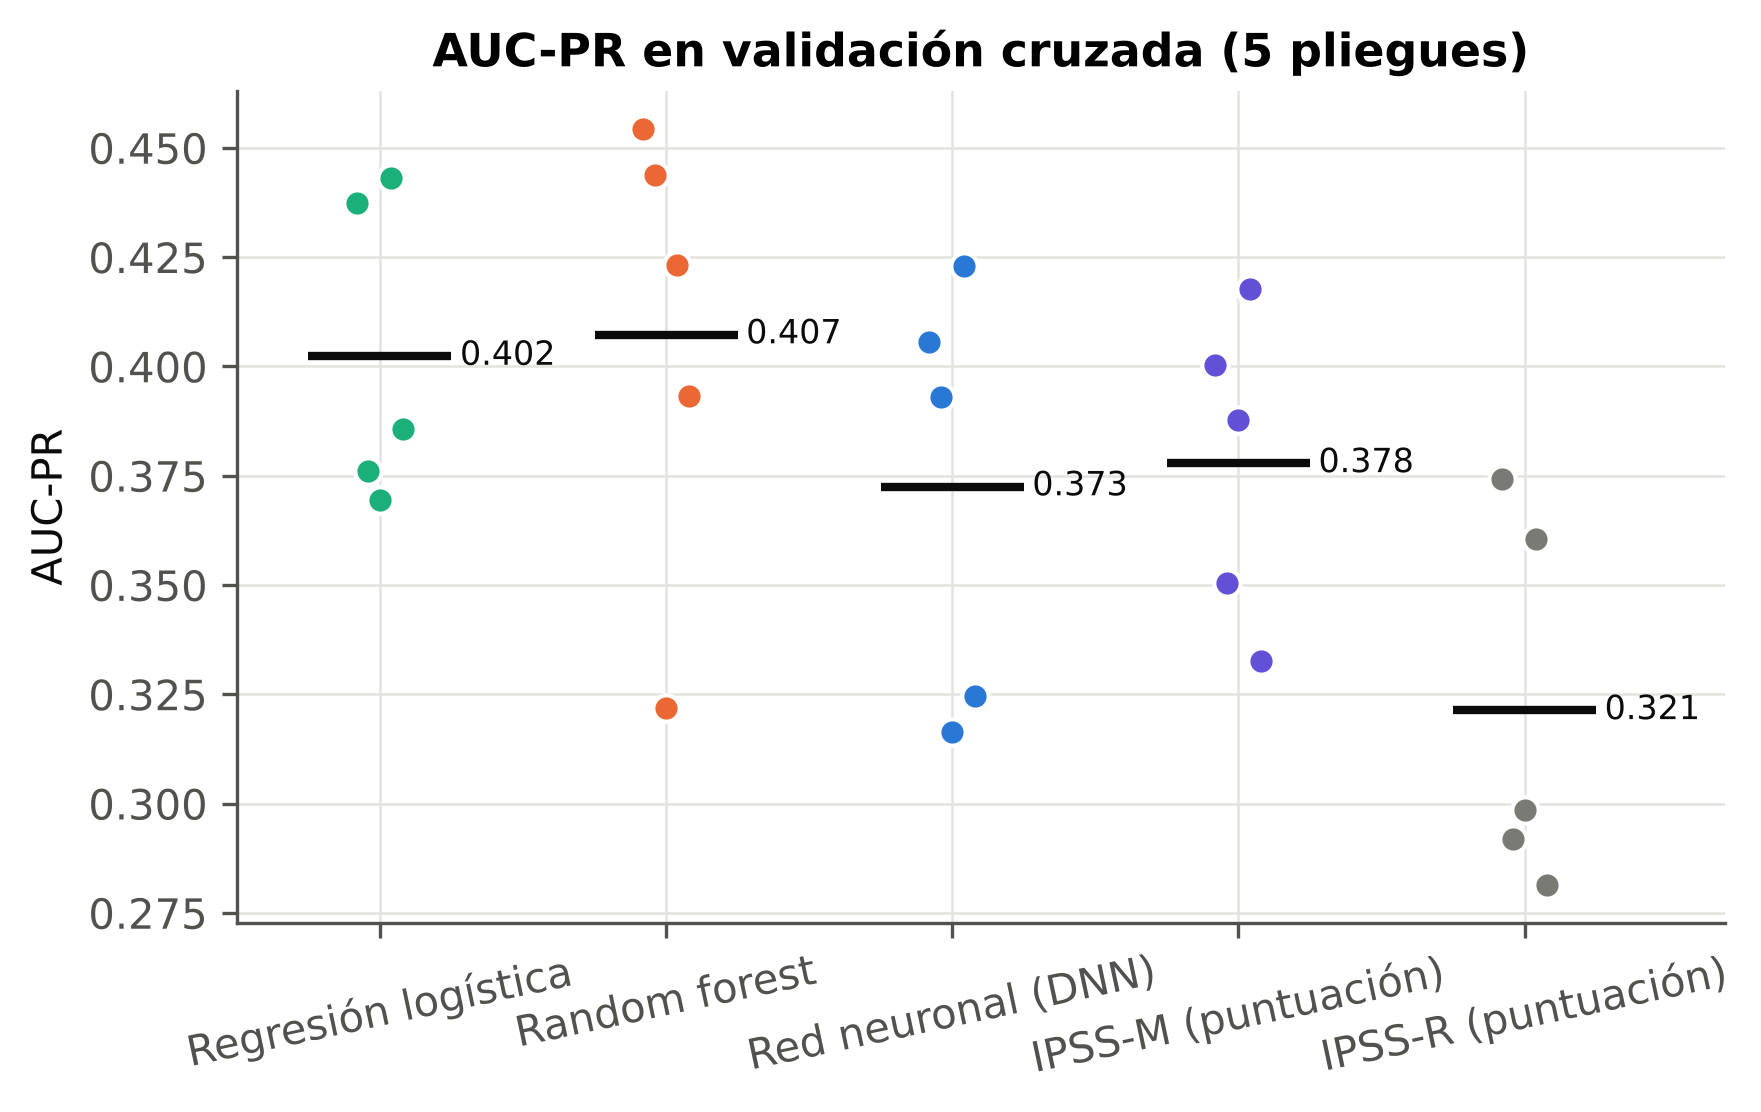

In [11]:
display(pd.read_csv(T / 'cv_resumen.csv', header=[0, 1], index_col=0)); fig('cv_auc_roc', 600); fig('cv_auc_pr', 600)

In [12]:
pd.read_csv(T / 'metricas_test_comparacion_IPSSM.csv')

,modelo,n,AUC-ROC,AUC-PR,Brier,calib_pendiente,calib_intercepto,umbral,sensibilidad,especificidad,VPP,VPN,F1,TP,FP,TN,FN,AUC-ROC IC2.5,AUC-ROC IC97.5,AUC-PR IC2.5,AUC-PR IC97.5
0,Regresión logística,470,0.765,0.452,0.125,1.043,0.057,0.398,0.718,0.634,0.302,0.910,0.425,61,141,244,24,0.709,0.815,0.371,0.564
1,Random forest,470,0.776,0.445,0.126,1.020,-0.004,0.302,0.765,0.652,0.327,0.926,0.458,65,134,251,20,0.726,0.822,0.363,0.538
2,Red neuronal (DNN),470,0.754,0.442,0.130,1.448,0.431,0.269,0.682,0.683,0.322,0.907,0.438,58,122,263,27,0.699,0.805,0.355,0.538
3,IPSS-M (puntuación),470,0.725,0.370,0.135,0.895,-0.112,-0.180,0.765,0.584,0.289,0.918,0.419,65,160,225,20,0.664,0.784,0.304,0.462
4,IPSS-R (puntuación),470,0.655,0.272,0.144,0.727,-0.366,4.000,0.600,0.654,0.277,0.881,0.379,51,133,252,34,0.594,0.715,0.228,0.343
5,IPSS-M (Alto/Muy alto),470,NaN,NaN,NaN,NaN,NaN,0.500,0.612,0.740,0.342,0.896,0.439,52,100,285,33,NaN,NaN,NaN,NaN


In [13]:
display(pd.read_csv(T / 'comparacion_delong.csv')); pd.read_csv(T / 'comparacion_bootstrap_aucpr.csv')

,comparación,AUC_a,AUC_b,ΔAUC,p_DeLong
0,Red neuronal (DNN) vs IPSS-M (puntuación),0.754,0.725,0.028,1.592e-01
1,Red neuronal (DNN) vs Random forest,0.754,0.776,-0.023,1.606e-01
2,Red neuronal (DNN) vs Regresión logística,0.754,0.765,-0.012,4.973e-01
3,Random forest vs IPSS-M (puntuación),0.776,0.725,0.051,1.820e-02
4,Regresión logística vs IPSS-M (puntuación),0.765,0.725,0.040,9.590e-02
5,IPSS-M (puntuación) vs IPSS-R (puntuación),0.725,0.655,0.071,8.000e-04


,comparación,métrica,diferencia_media,IC2.5,IC97.5,p_bootstrap
0,Red neuronal (DNN) − IPSS-M (puntuación),AUC-PR,0.071,-7.000e-04,0.144,0.055
1,Red neuronal (DNN) − Random forest,AUC-PR,-0.003,-7.920e-02,0.074,0.933
2,Red neuronal (DNN) − Regresión logística,AUC-PR,-0.015,-7.440e-02,0.040,0.627


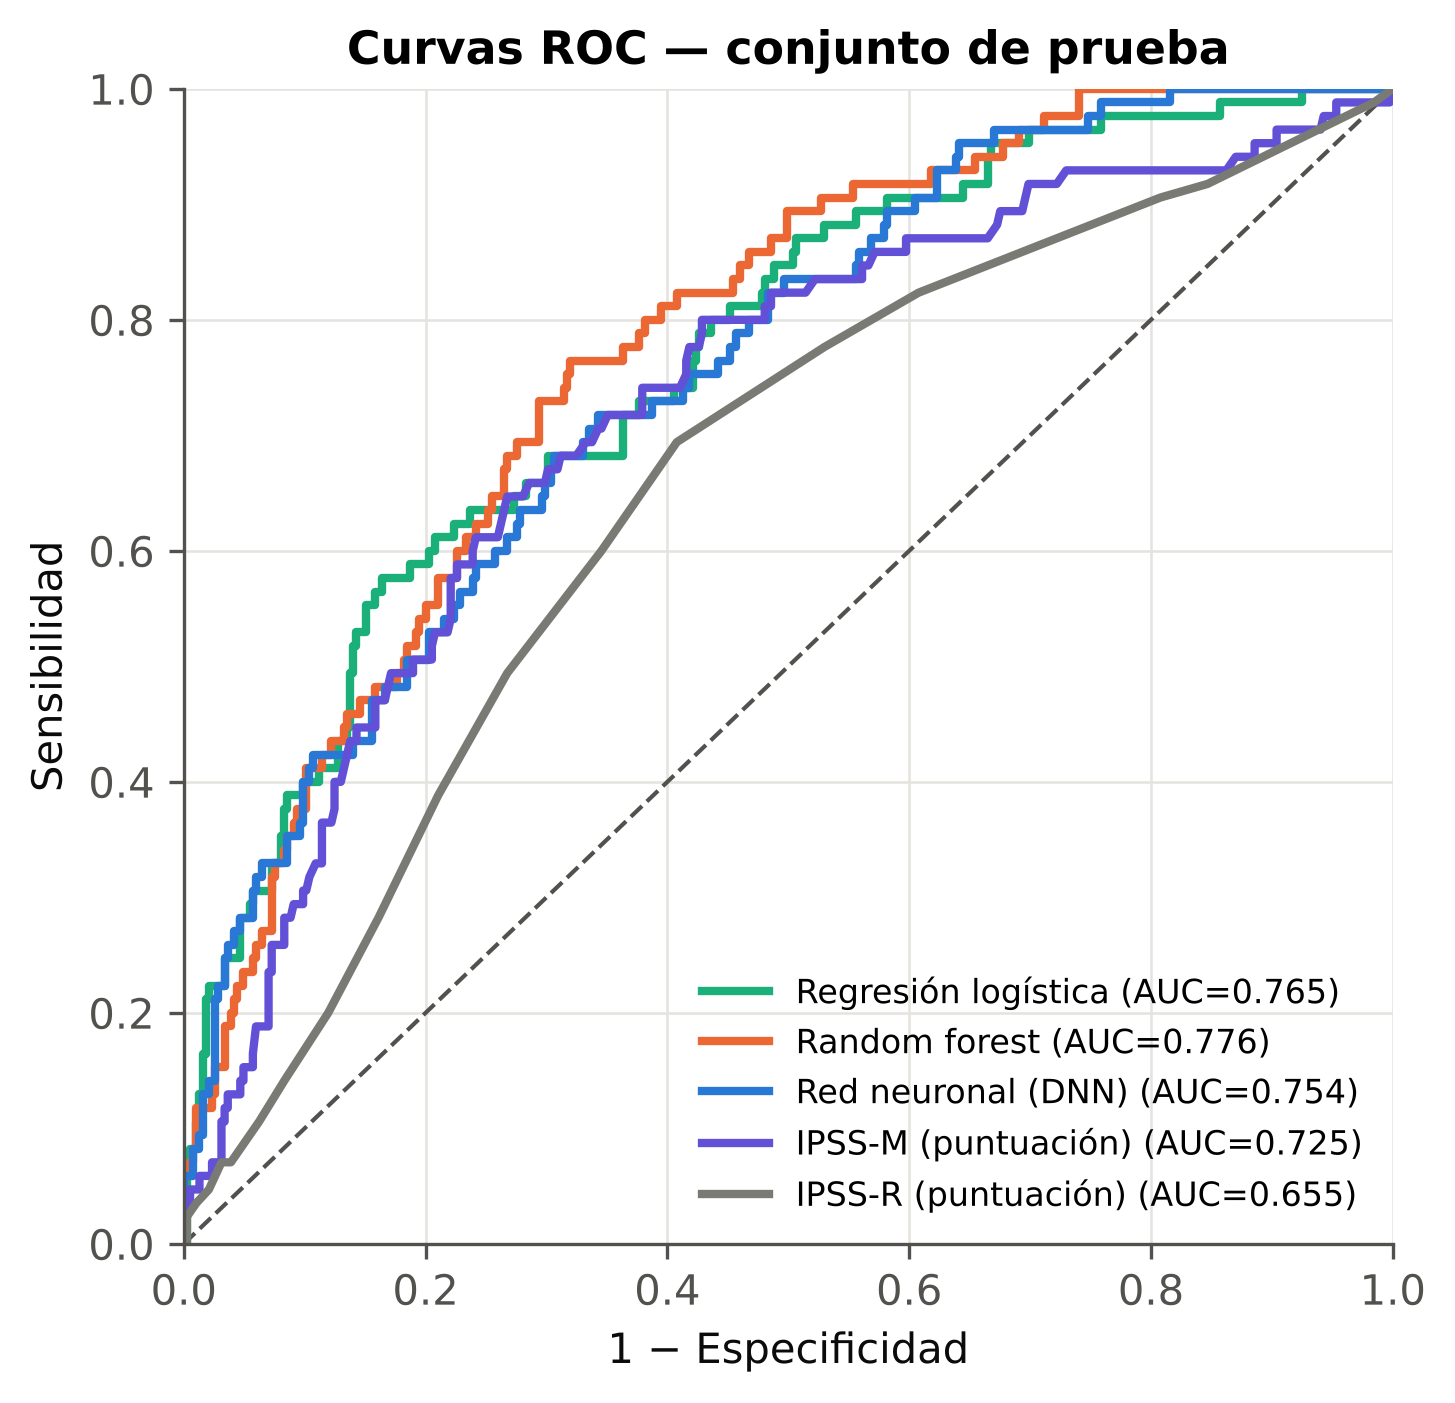

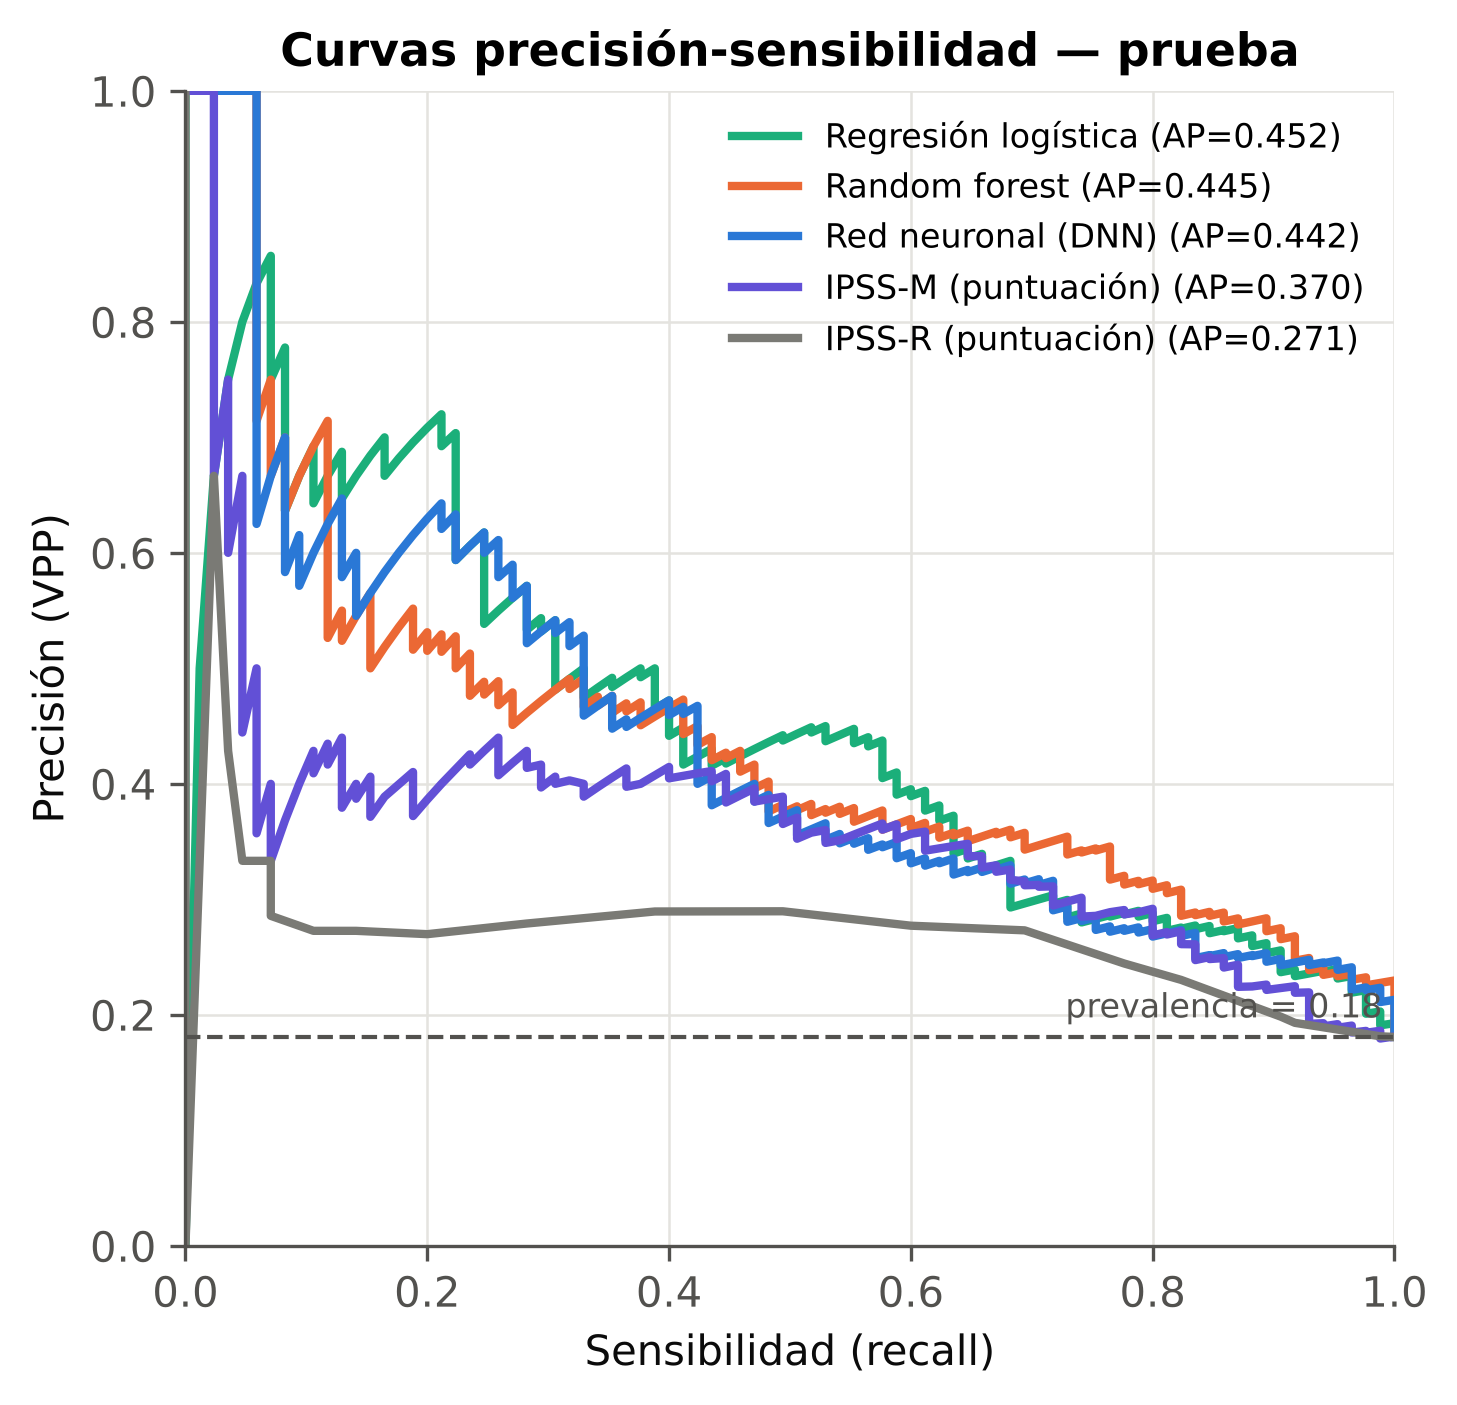

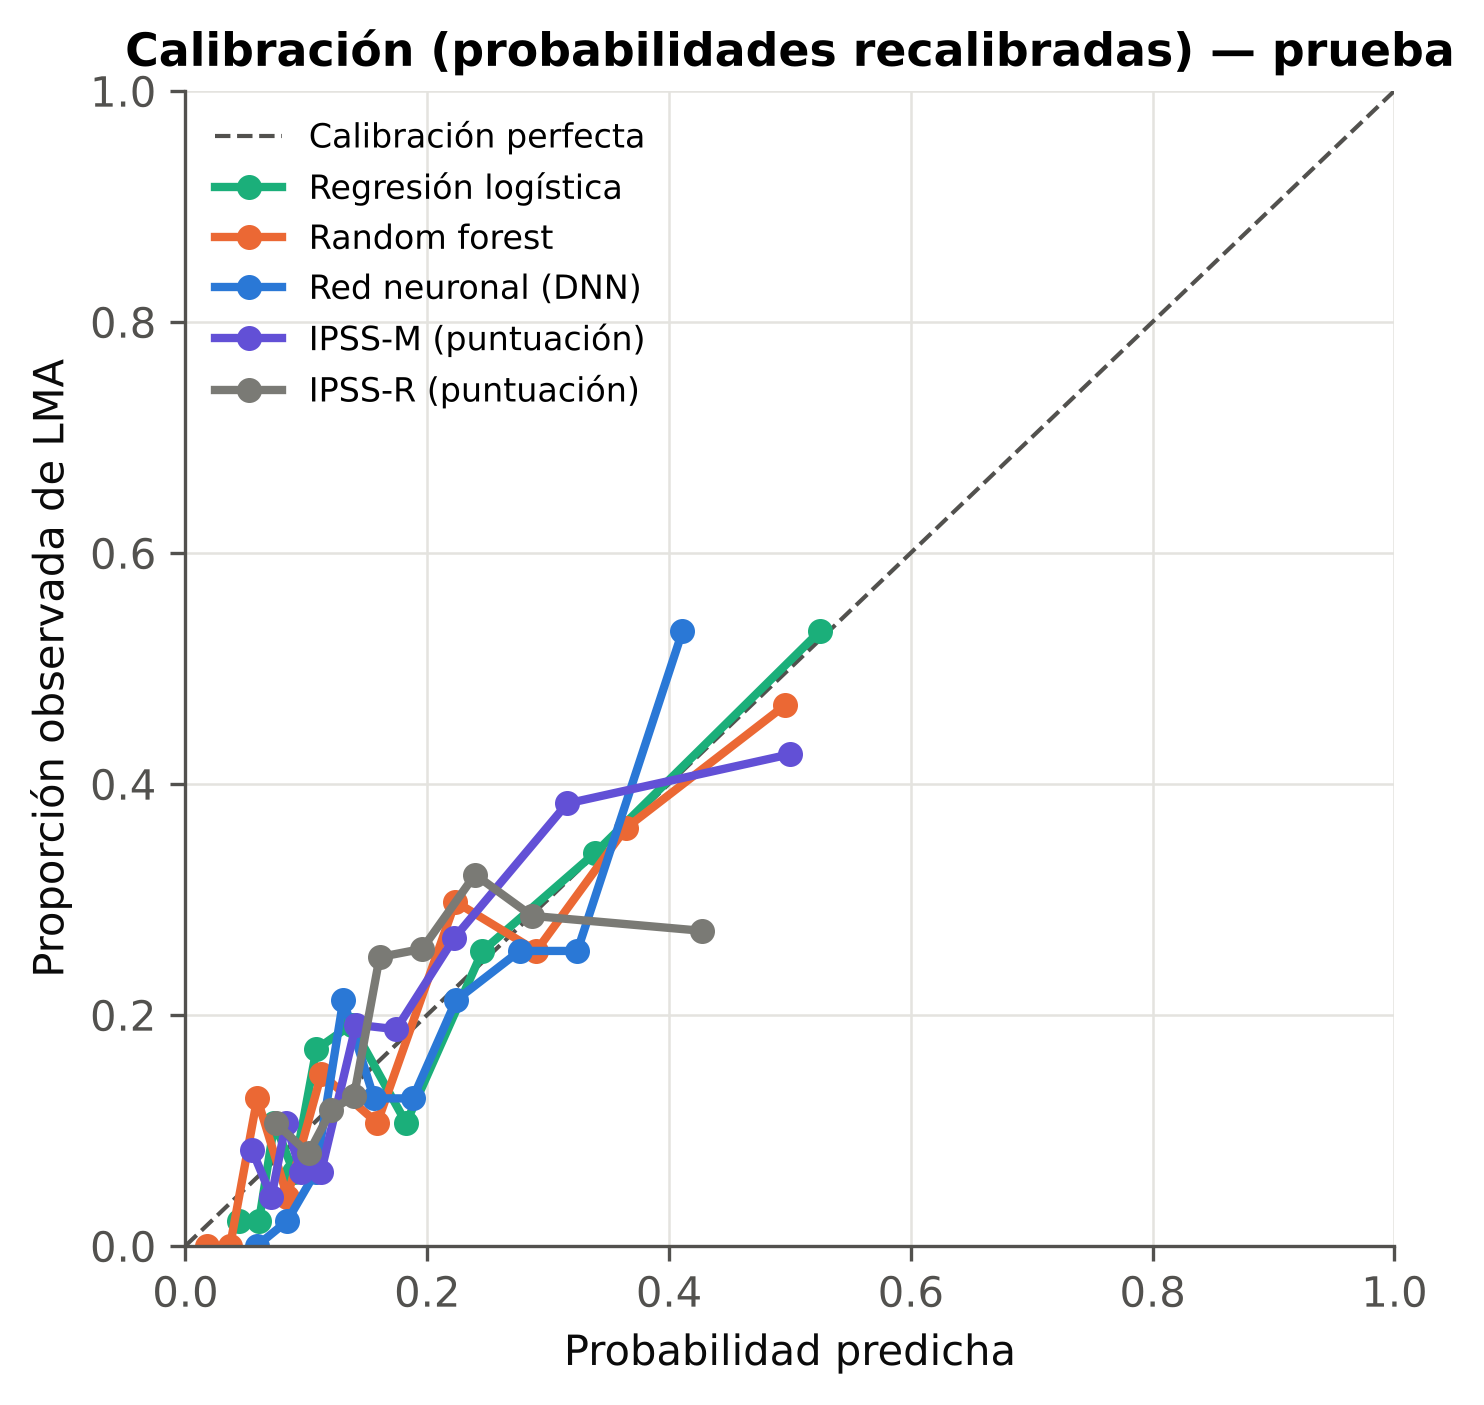

In [14]:
fig('roc_test', 480); fig('pr_test', 480); fig('calibracion_test', 480)

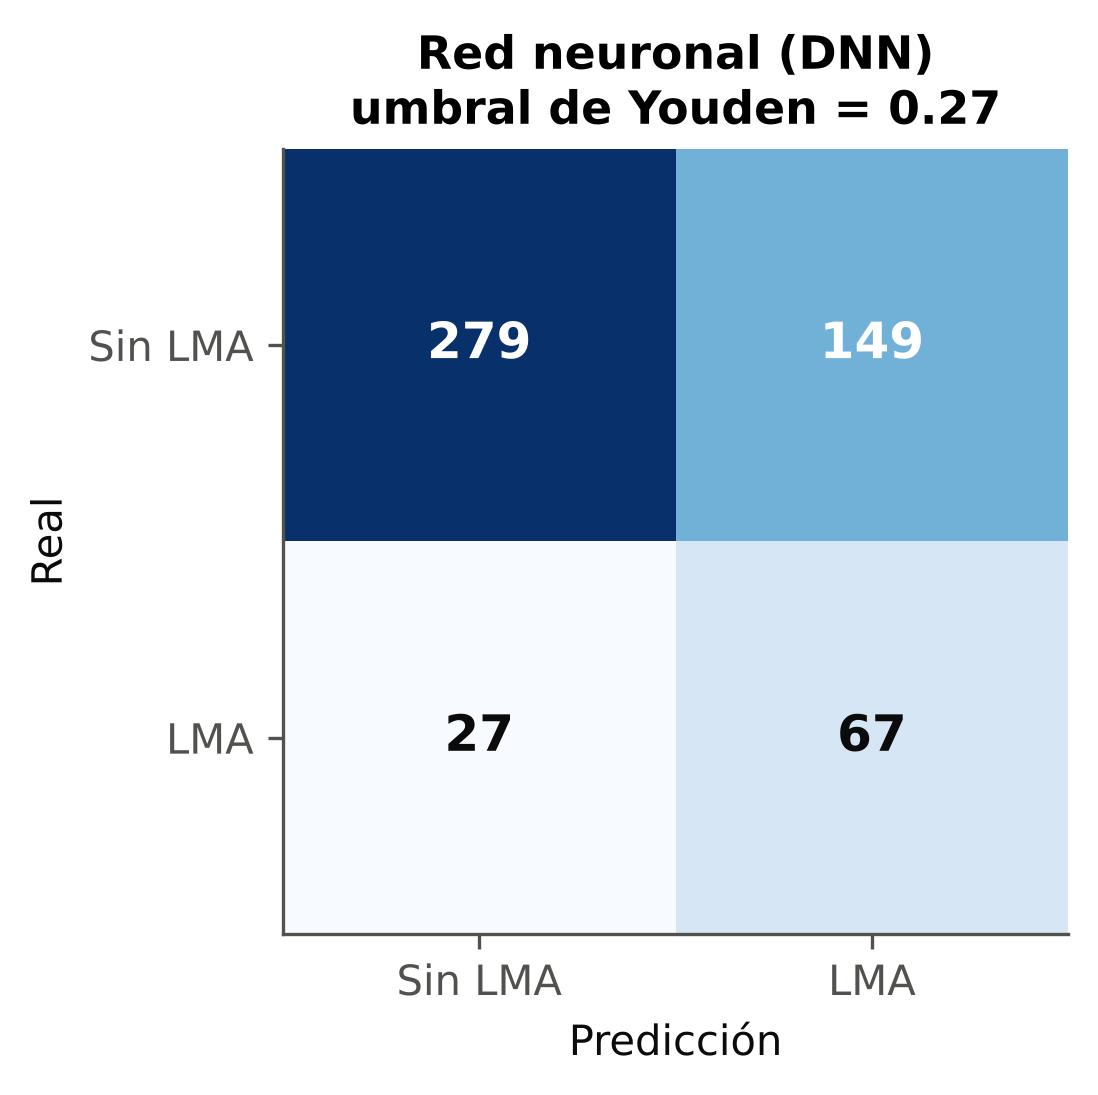

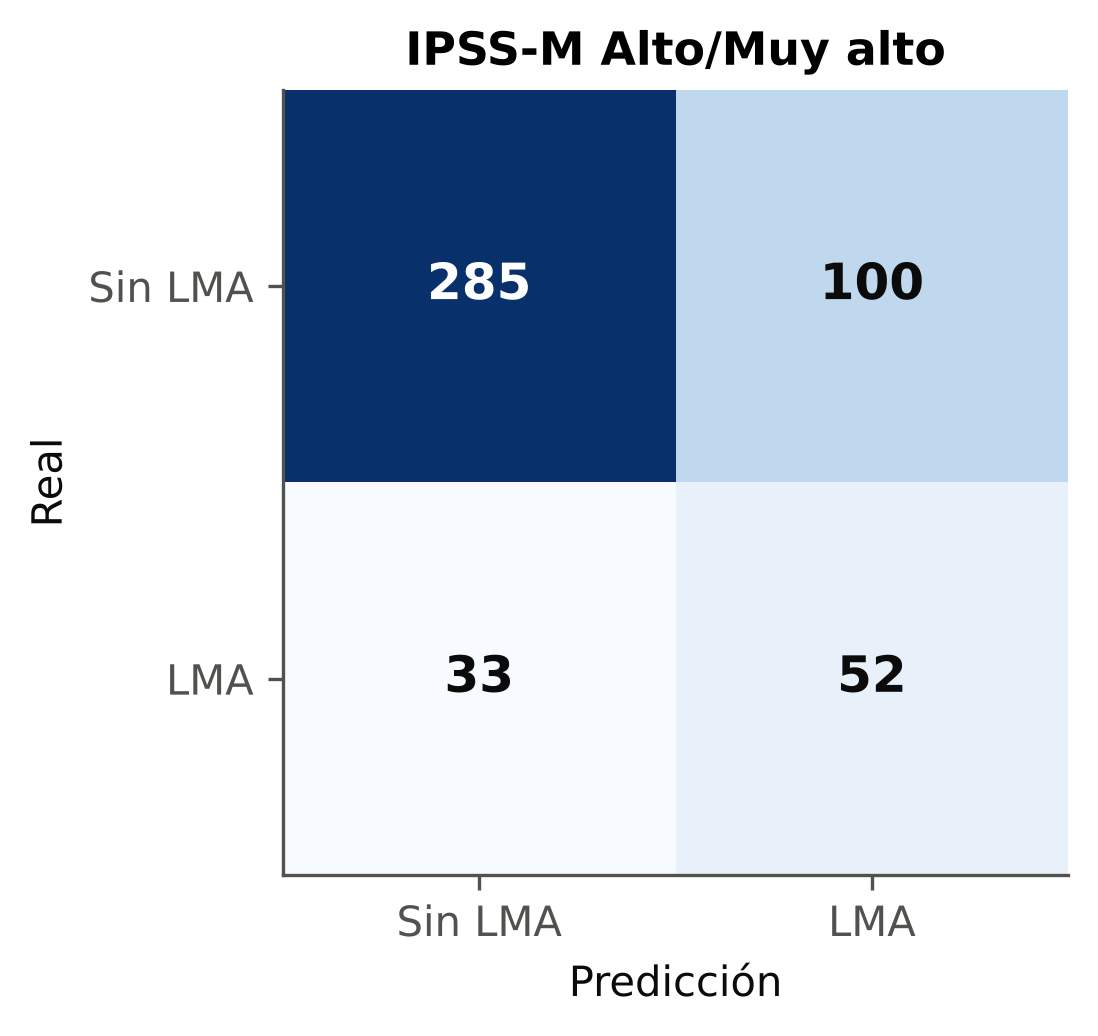

In [15]:
fig('matriz_confusion_dnn', 330); fig('matriz_confusion_ipssm', 330)

## 5. Estratificación del riesgo y sensibilidad

,clasificación,grupo,n,% del total,LMA observadas,% LMA,incidencia acumulada LMA 3 años %
0,IPSS-M (3 grupos),Bajo,218,45.9,17,7.8,7.7
1,IPSS-M (3 grupos),Intermedio,102,21.5,16,15.7,16.7
2,IPSS-M (3 grupos),Alto,155,32.6,53,34.2,39.8
3,Red neuronal (3 grupos),Bajo,277,58.3,24,8.7,9.7
4,Red neuronal (3 grupos),Intermedio,135,28.4,33,24.4,26.1
5,Red neuronal (3 grupos),Alto,63,13.3,29,46.0,51.5


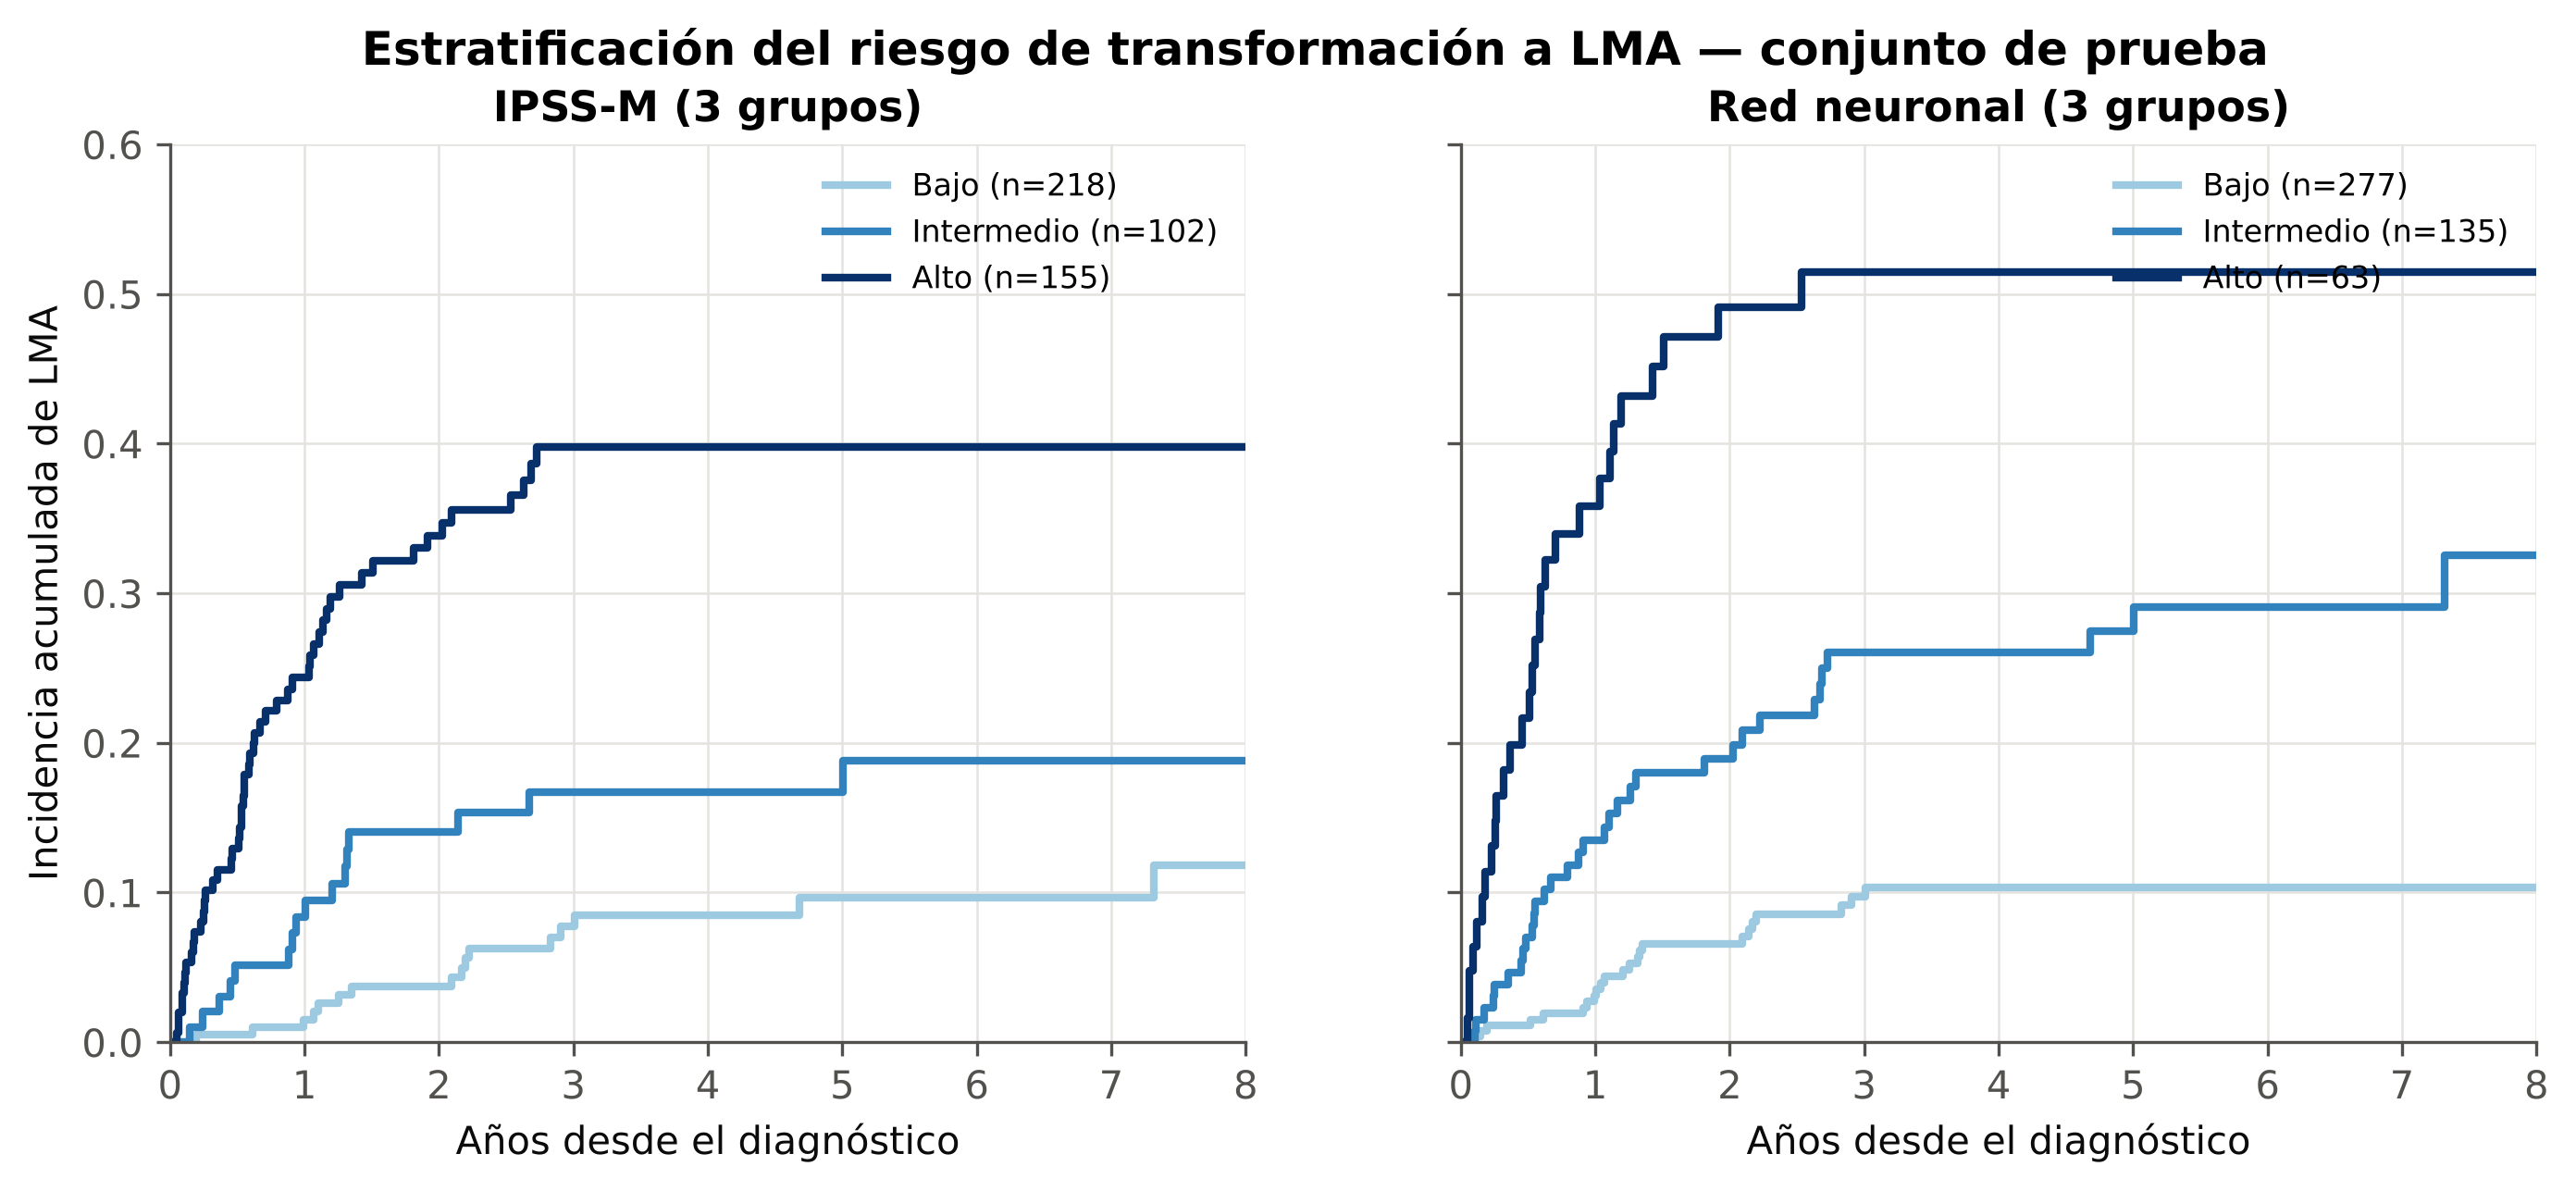

In [16]:
display(pd.read_csv(T / 'estratificacion_grupos_riesgo.csv')); fig('estratificacion_dnn_vs_ipssm', 900)

In [17]:
display(pd.read_csv(T / 'reclasificacion_ipssm_vs_dnn_tasa_LMA.csv', index_col=0))
display(pd.read_csv(T / 'indice_C_tiempo_LMA.csv', index_col=0))
pd.read_csv(T / 'sensibilidad_horizonte_36m.csv')

,Bajo,Intermedio,Alto
grupo_IPSSM,,,
Bajo,6.5,22.2,NaN
Intermedio,11.5,18.9,50.0
Alto,25.0,27.5,45.8


,indice_C
Red neuronal (DNN),0.785
Random forest,0.813
Regresión logística,0.789
IPSS-M (puntuación),0.795


,modelo,n,eventos,AUC-ROC,AUC-PR
0,Regresión logística,1842,430,0.760,0.470
1,Random forest,1842,430,0.774,0.473
2,Red neuronal (DNN),1842,430,0.745,0.445
3,IPSS-M (puntuación)*,1697,392,0.745,0.438


## 6. Interpretabilidad con SHAP (OE4)

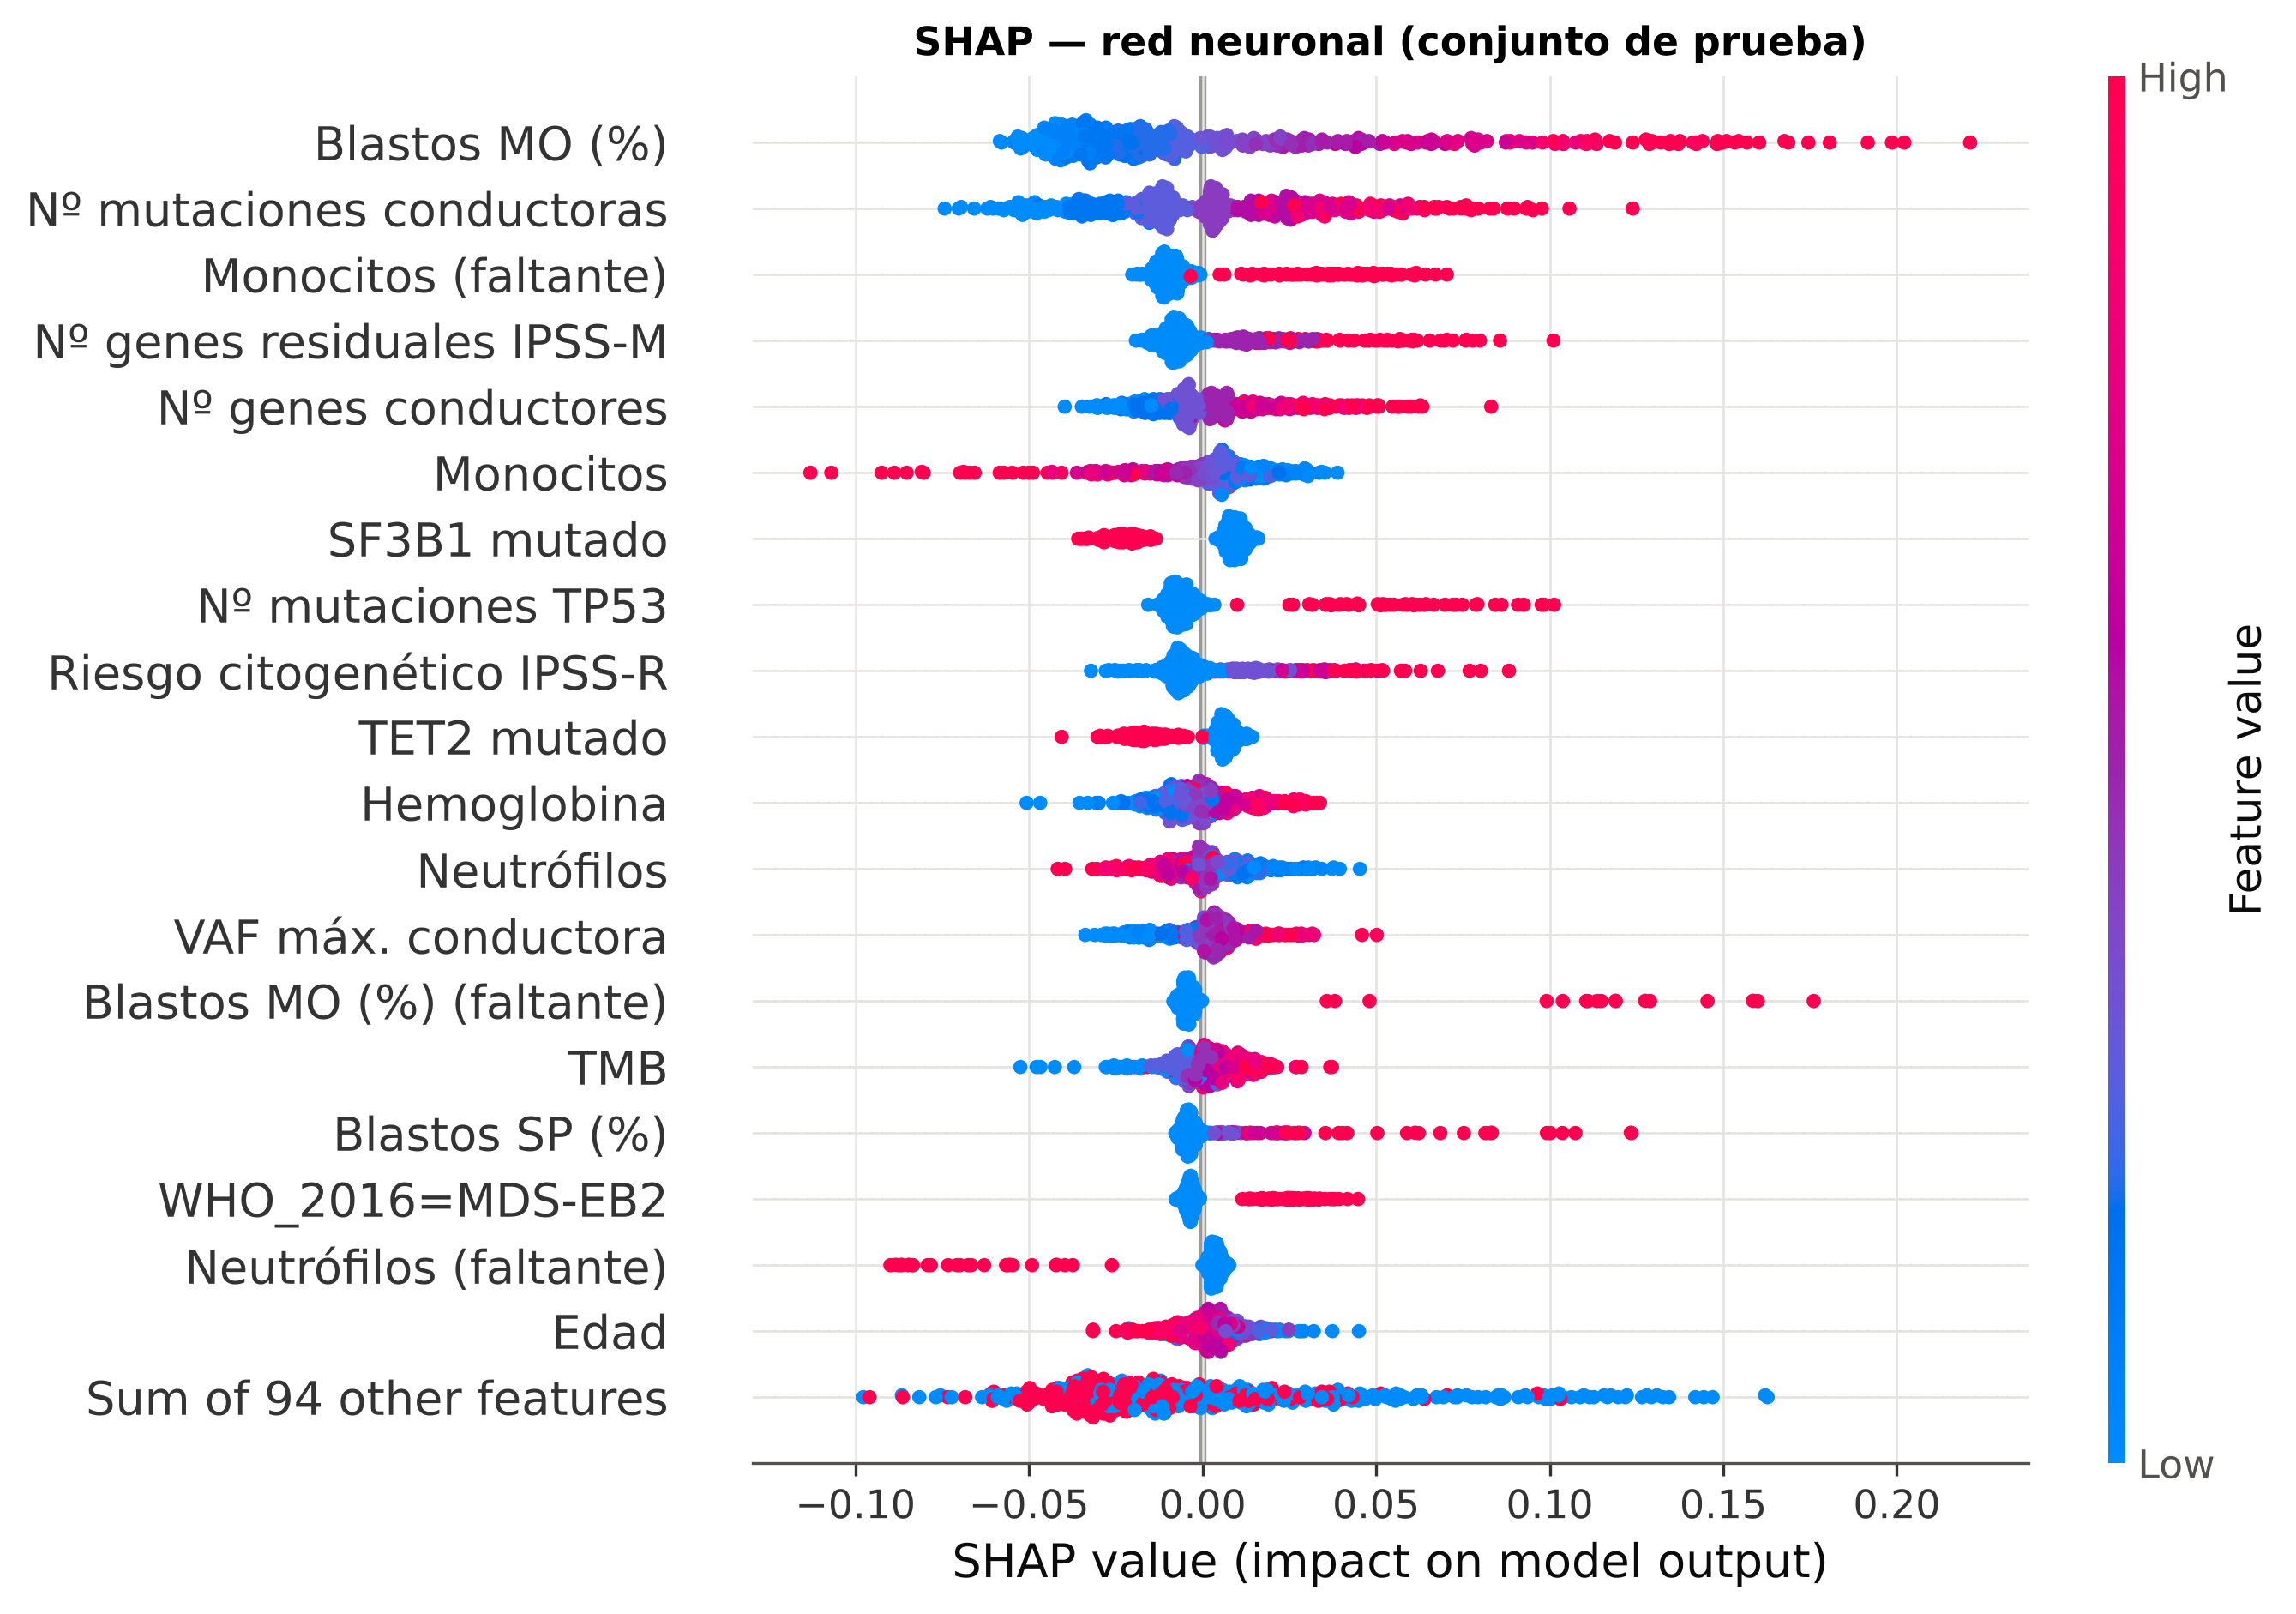

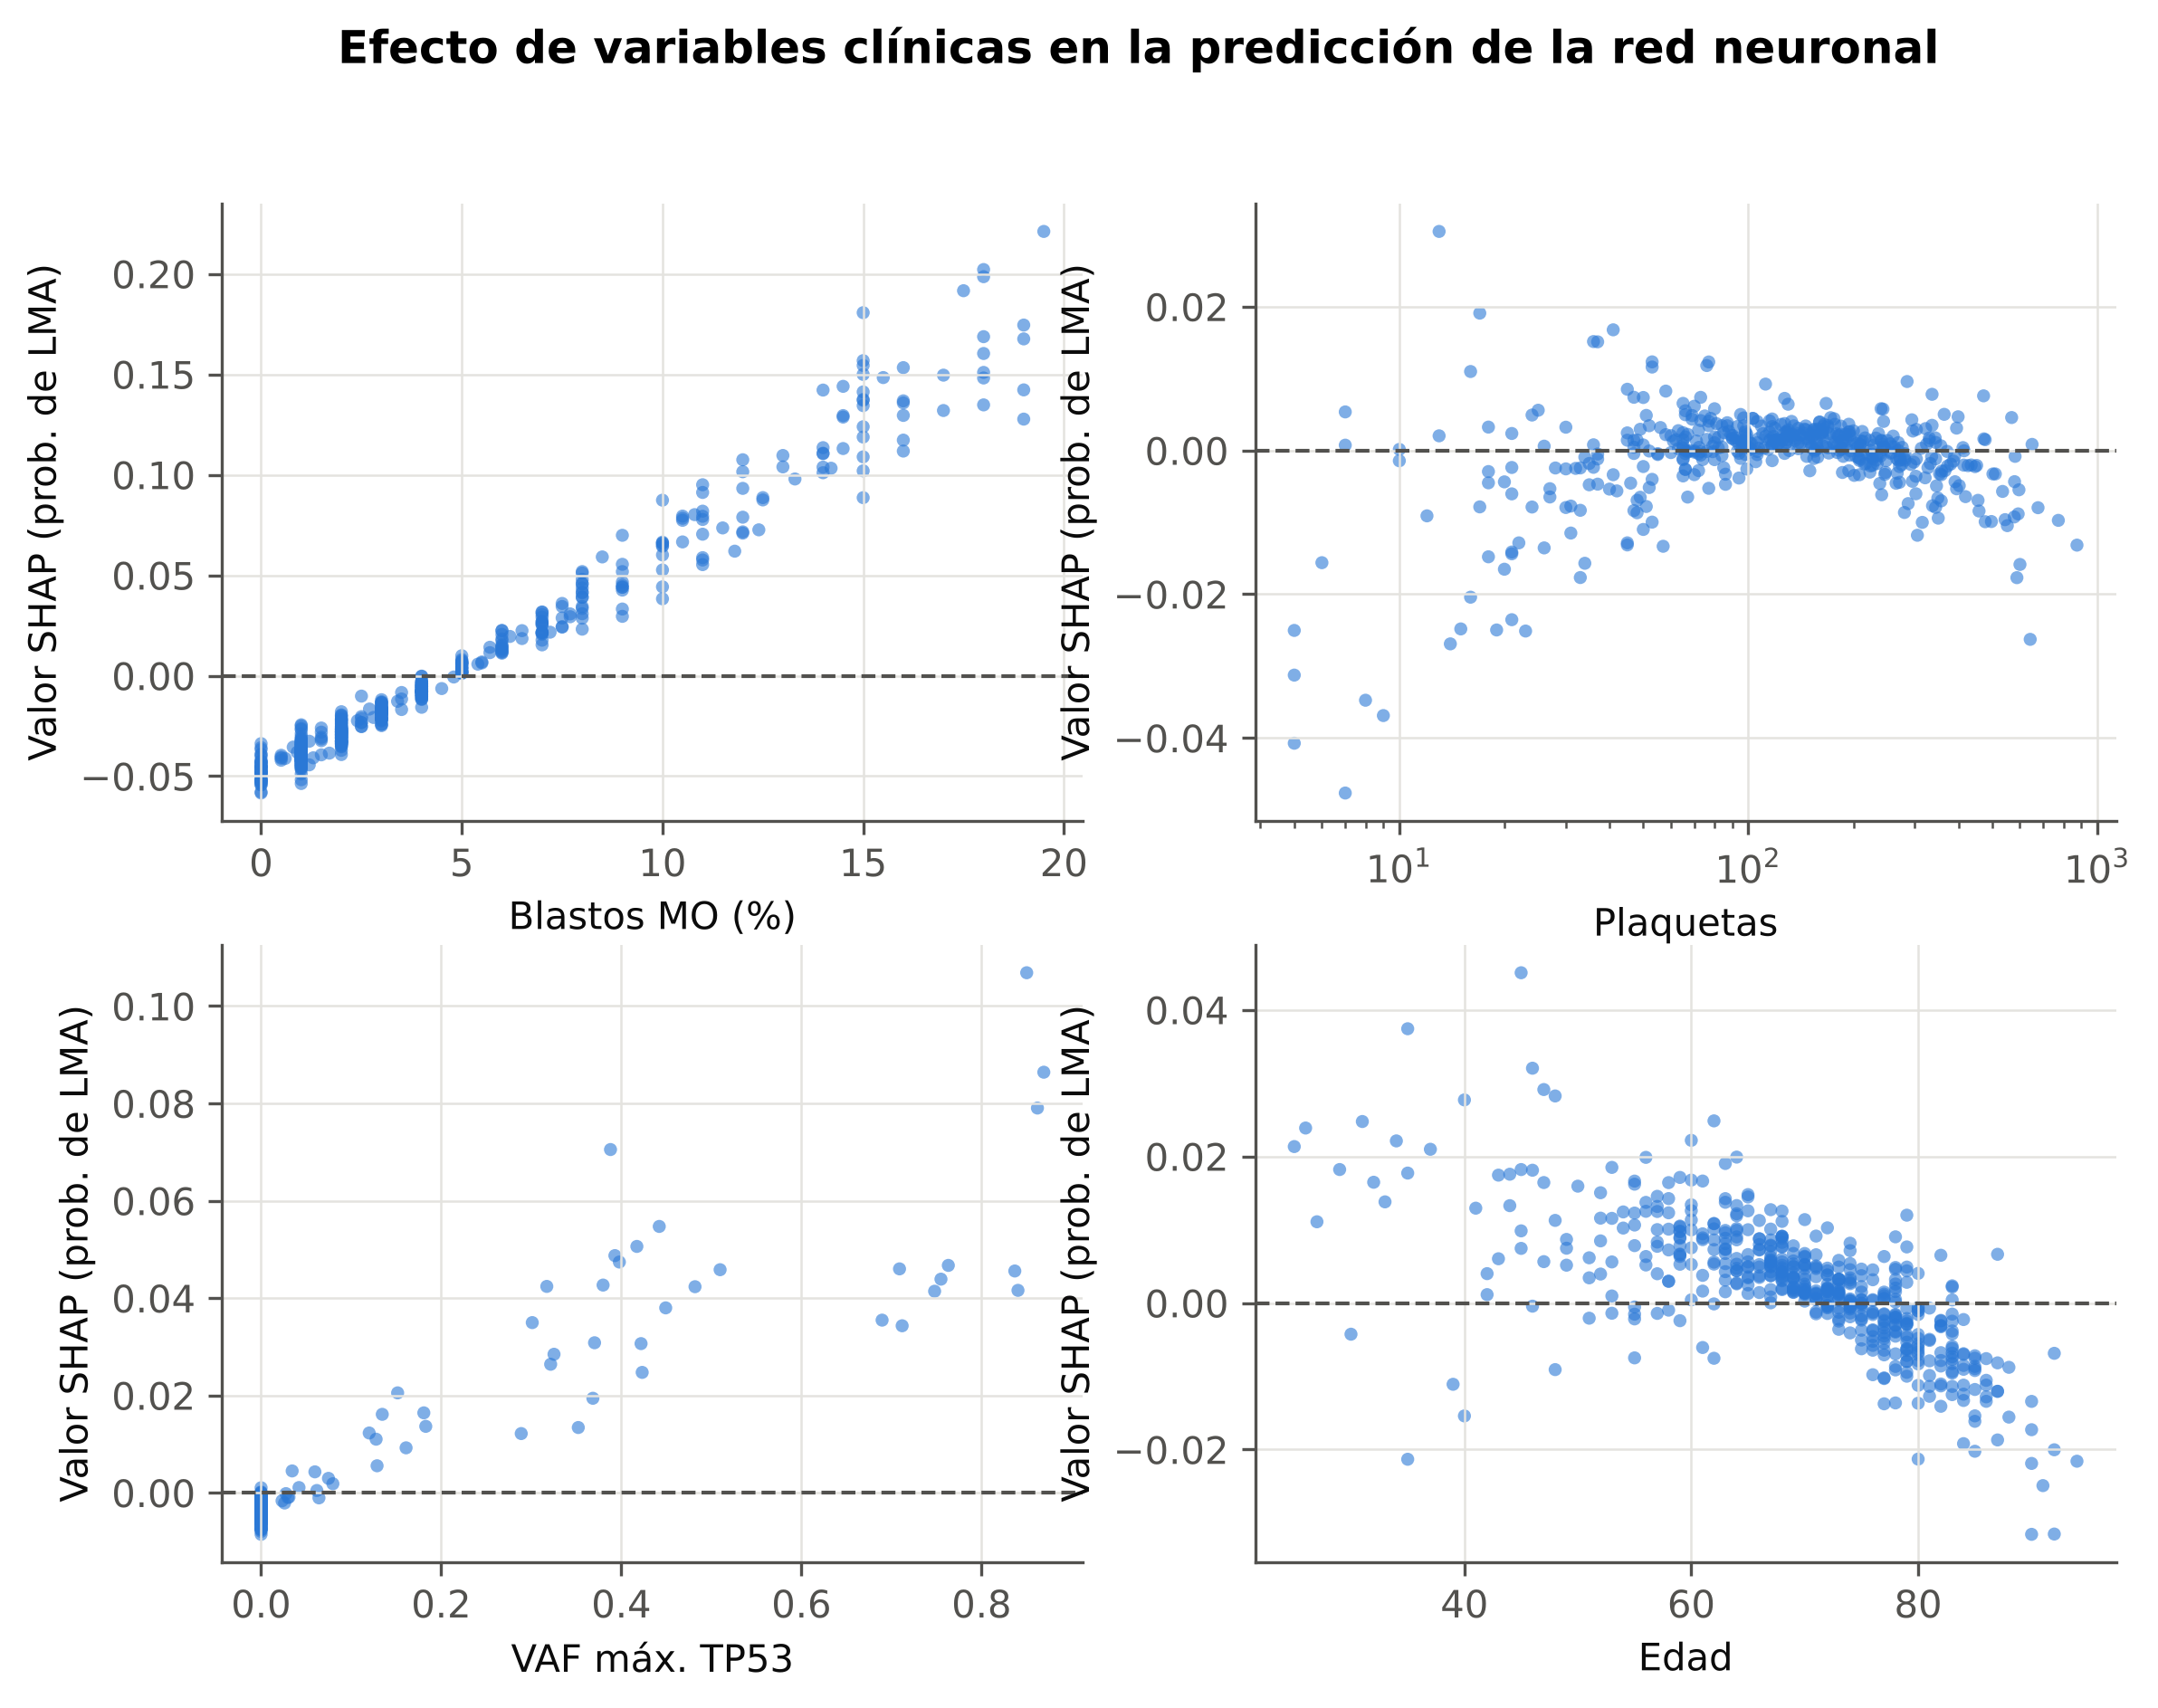

In [18]:
fig('shap_dnn_beeswarm', 700); fig('shap_dnn_dependencia', 750)

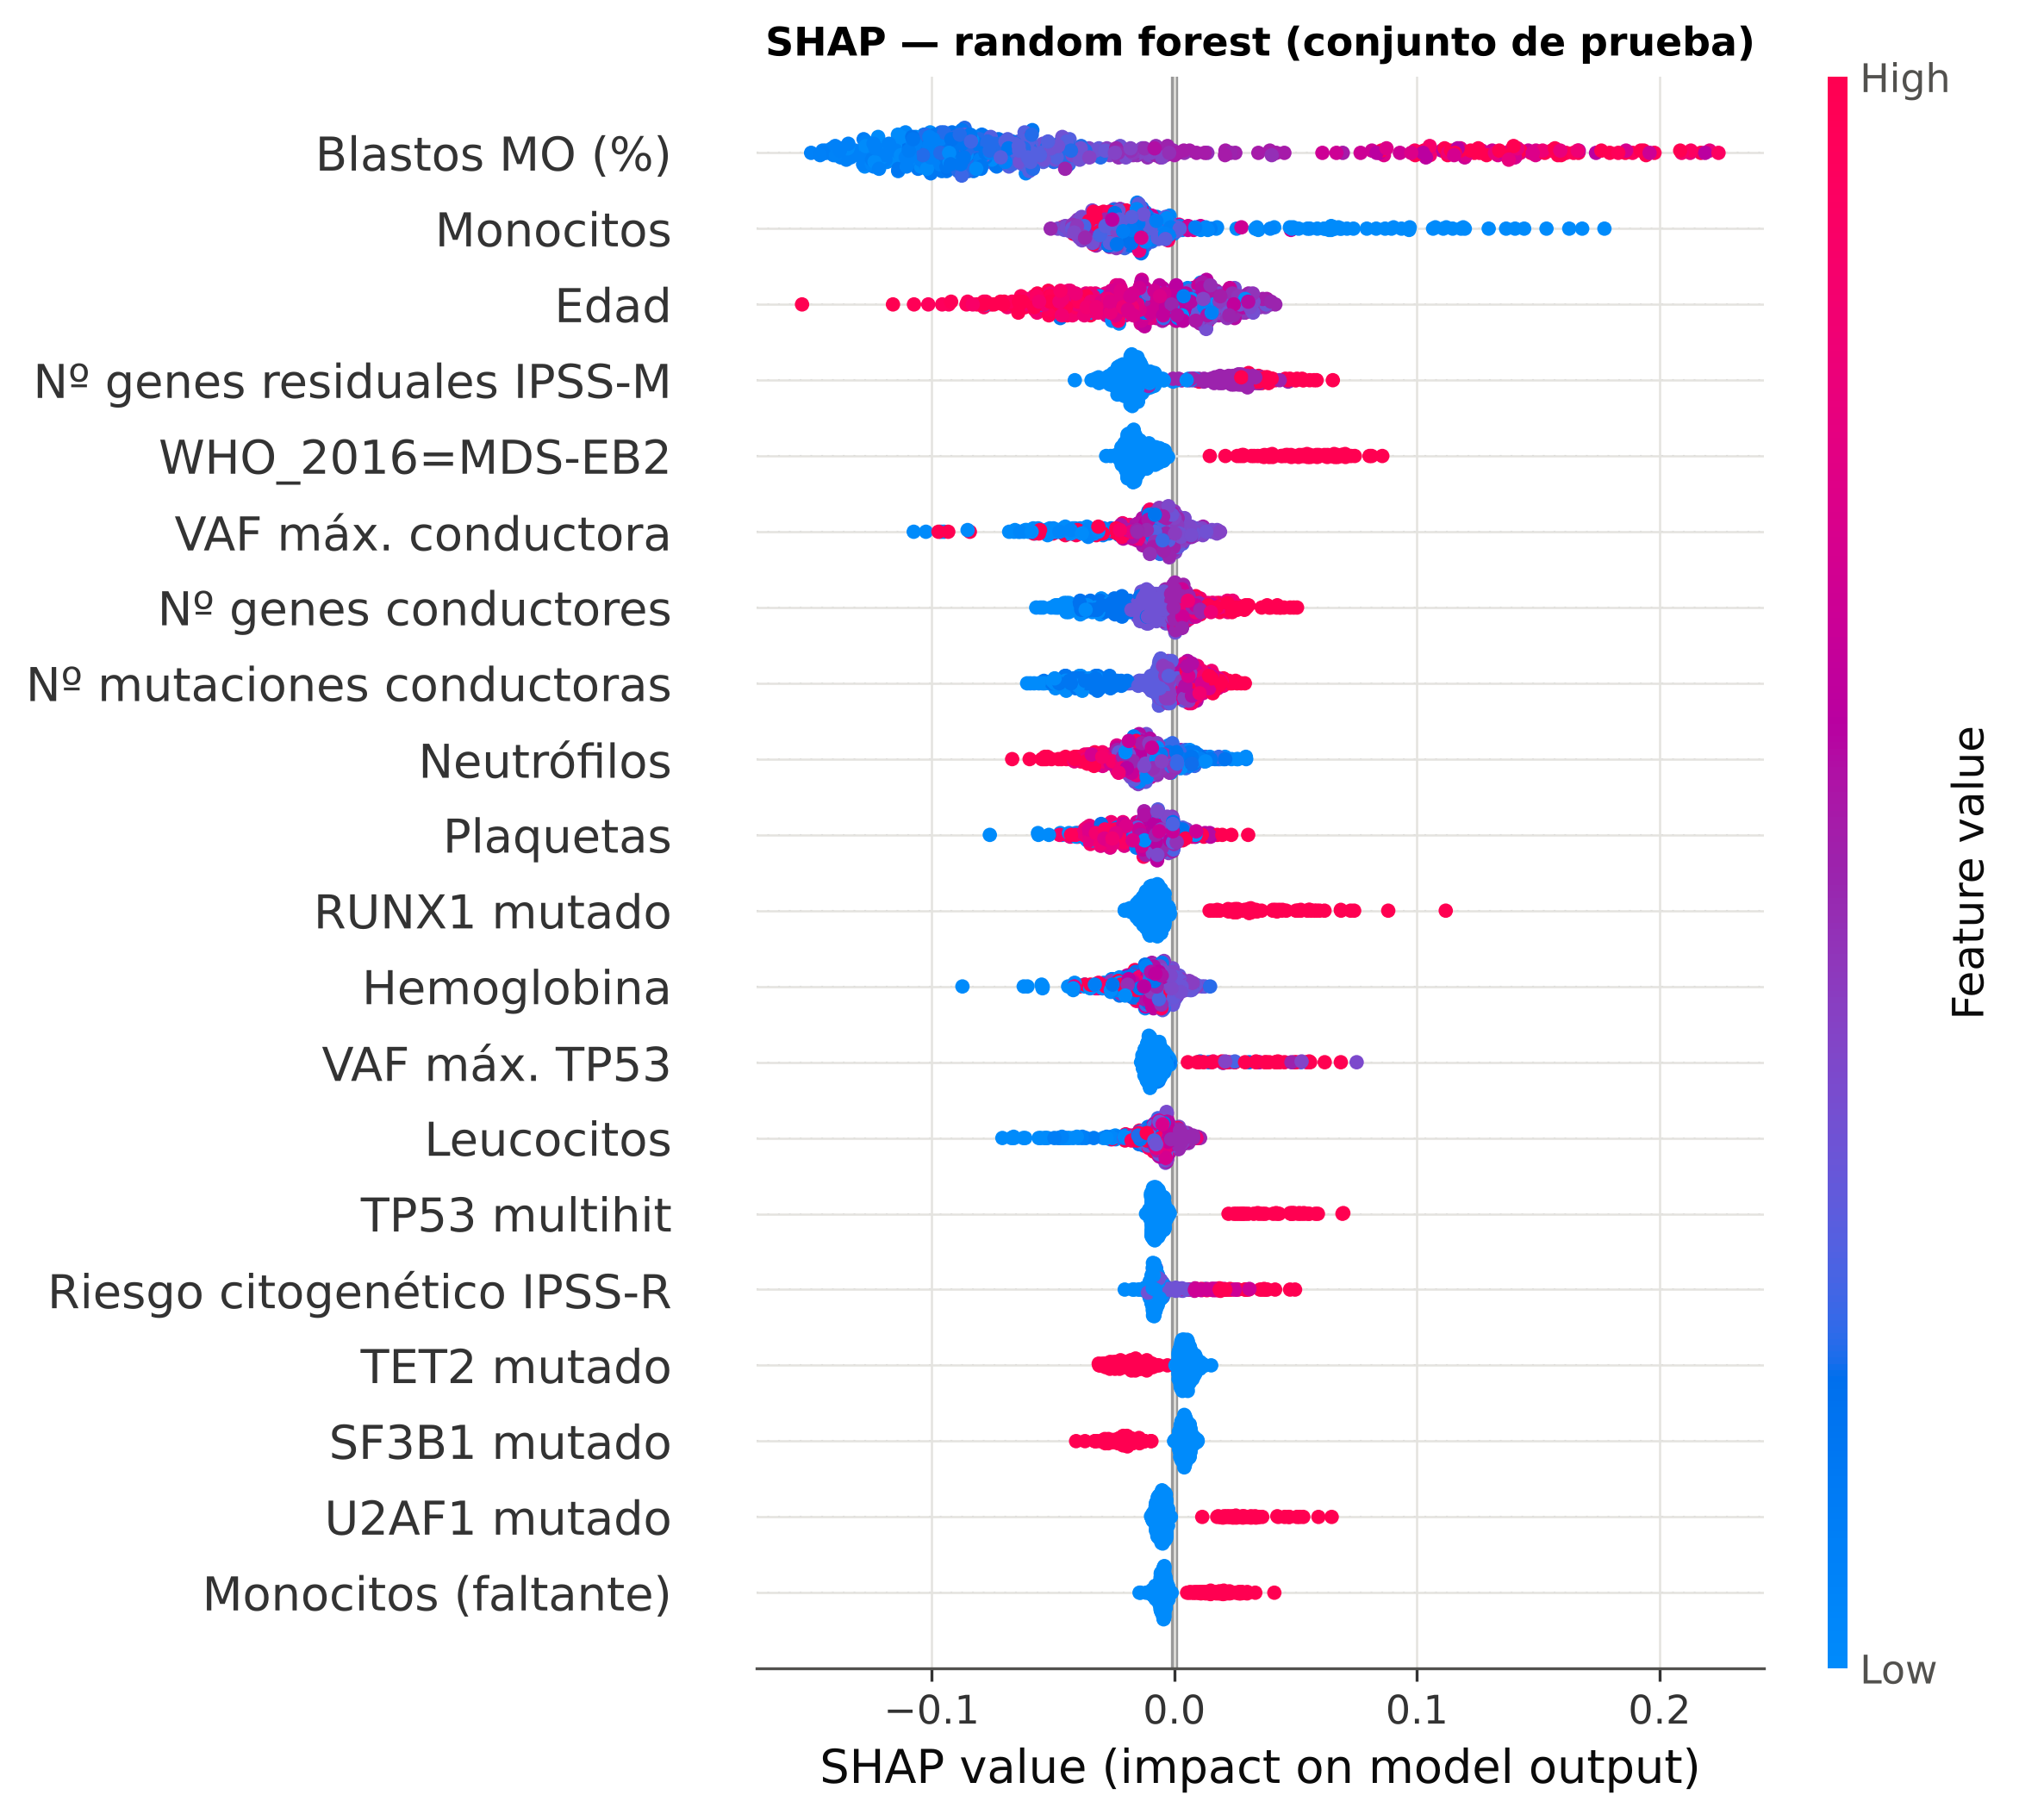

,variable,SHAP_DNN,SHAP_RF,LR_abs_coef,rank_SHAP_DNN,rank_SHAP_RF,rank_LR_abs_coef,direccion_DNN
0,Blastos MO (%),0.040,9.011e-02,0.511,1,1,4,↑ riesgo
1,Nº mutaciones conductoras,0.028,1.522e-02,0.081,2,8,71,↑ riesgo
2,Monocitos (faltante),0.015,7.460e-03,0.193,3,20,40,↑ riesgo
3,Nº genes residuales IPSS-M,0.014,2.112e-02,0.102,4,4,64,↑ riesgo
4,Nº genes conductores,0.014,1.538e-02,0.246,5,7,26,↑ riesgo
5,Monocitos,0.013,2.760e-02,0.153,6,2,51,↓ riesgo
6,SF3B1 mutado,0.013,8.660e-03,0.126,7,18,56,↓ riesgo
7,Nº mutaciones TP53,0.011,3.380e-03,0.144,8,29,53,↑ riesgo
8,Riesgo citogenético IPSS-R,0.011,8.980e-03,0.139,9,16,54,↑ riesgo
9,TET2 mutado,0.010,8.840e-03,0.300,10,17,19,↓ riesgo


In [19]:
fig('shap_rf_beeswarm', 650); pd.read_csv(T / 'importancia_variables_comparada.csv').head(20)